# Prediksi Harga Properti — REVISI 4

**Urutan pakai (wajib):**
1. Set `DEBUG = True` → *Run all* (±10–20 menit). Tujuannya hanya memastikan semua cell berjalan tanpa error. **Jangan pakai angkanya.**
2. Set `DEBUG = False`, hapus file `optuna_*.db` lama, lalu *Run all*. Jika Colab terputus, jalankan lagi dari atas: tuning Optuna **dilanjutkan** dari trial terakhir (file `.db` jangan dihapus di tengah proses).
3. Semua tabel untuk manuskrip tersimpan otomatis di folder `outputs/` (CSV/JSON) dan di-zip di cell terakhir.

**Perubahan dari REVISI_3 → jawaban untuk review**

| Review | Masalah di REVISI_3 | Perbaikan di REVISI_4 |
|---|---|---|
| C3 | Hold-out ZIP: R² log 0,54 / USD 0,37. ZIP baru jatuh ke median global (konstan) | Fitur spasial **hierarkis** (ZIP → ZIP3 → state, shrinkage per level) + opsi OOF **per-grup ZIP**; geo-CV 5-fold, 3 varian dibandingkan |
| C2 | OOF sudah benar, tetapi perbandingan *leaky vs leak-free* hilang dari ablation | Ablation 5 baris termasuk varian **leaky** + *negative-control* (target diacak → R² harus ≈ 0) |
| C1 | Pembanding Wilcoxon dipilih setelah melihat hasil; bootstrap per baris | Pembanding ditetapkan di awal (XGBoost vs semua), **bootstrap per cluster ZIP**, koreksi Holm/Bonferroni |
| C4 | Nilai `status` sebenarnya `for_sale`/`sold`; harga campuran listing + transaksi | Distribusi `status`, tabel pembersihan per langkah, metrik **per status** |
| Audit | Metrik MAPE/COD tidak ada di tabel akhir; train R² tidak sebanding; N_TRIALS 30 vs teks 15; LightGBM `subsample` tidak aktif | Tabel metrik lengkap, train R² memakai fitur OOF, semua konsisten, ruang pencarian diperbaiki |
| C5 | Belum ada artefak reproduksi | Versi library, seed, hyperparameter, riwayat trial, prediksi test → `outputs/` |

# **1. Informasi Dataset**

Proyek ini menggunakan dataset Kaggle **USA Real Estate Dataset** Real Estate Housing Dataset (Realtor Data) yang diperoleh dari platform listing properti realtor.com. Dataset ini berisi informasi terkait properti yang dijual maupun yang telah terjual di berbagai wilayah di Amerika Serikat.

**Tujuan Dataset**

Dataset ini digunakan untuk menganalisis hubungan antara karakteristik properti dengan harga jual, serta membangun model machine learning untuk prediksi harga properti (house price prediction).

**Sumber Dataset**
*   Dataset diambil dari Kaggle: https://www.kaggle.com/datasets/ahmedshahriarsakib/usa-real-estate-dataset
*   Dataset dikumpulkan dari: https://www.realtor.com/

Platform realtor ini merupakan salah satu website listing properti terbesar di Amerika Serikat dengan lebih dari 100 juta pengguna aktif per bulan.

**Struktur Dataset**

Dataset terdiri dari: **2.226.382 baris** dan **10 fitur utama**.

Setiap baris merepresentasikan satu properti.

**Fitur Dataset**

**1. Fitur Properti**
  * bed → jumlah kamar tidur
  * bath → jumlah kamar mandi
  * house_size → luas bangunan (square feet)
  * acre_lot → luas tanah (acre)

**2. Fitur Lokasi**
  * city → nama kota
  * state → negara bagian
  * zip_code → kode pos

**3. Fitur Listing**
  * brokered by → agen/broker (sudah diencoding)
  * status → status listing. Nilai aktual di data: `for_sale` dan `sold` (cek distribusi lengkap di bagian 3 — jangan memakai istilah "ready for sale/ready to build")

**4. Fitur Historis**
  * prev_sold_date → tanggal terakhir properti dijual

**5. Fitur Identitas**
  * street → alamat jalan (sudah diencoding untuk menjaga privasi)

**Target Variabel**
* price (Harga Properti)
  * **Campuran**: harga *listing* (status `for_sale`) dan harga *transaksi* (status `sold`). Karena itu di paper istilah target harus konsisten (mis. "listing/sale price, status-dependent"), `status` dipakai sebagai fitur, dan hasil dilaporkan juga per status
  * Bertipe numerik (regresi)

**Karakteristik Dataset**
* Dataset berskala besar (big data, >2 juta data)
* Mengandung:
  * data numerik
  * data kategorikal
  * data temporal (tanggal)
* Cocok untuk:
  * machine learning regression
  * ensemble learning
  * analisis big data


## **Data di sampling menjadi 400k**

# **2. Import Packages/Library yang Digunakan**

Pada bagian ini dilakukan proses import seluruh library yang diperlukan untuk menjalankan proyek Prediksi Harga Properti.

In [ ]:
# Install (Colab). Di luar Colab pasang manual: pip install xgboost lightgbm catboost shap optuna gdown
!pip install xgboost lightgbm catboost shap optuna gdown -q

import os, sys, gc, json, random, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn, scipy
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, KFold, GroupKFold,
                                     GroupShuffleSplit, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from scipy.stats import wilcoxon

import shap, optuna, xgboost, lightgbm, catboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# ===================== KONFIGURASI =====================
DEBUG        = False      # True = uji cepat (sampel kecil, 2 trial). Angkanya JANGAN dipakai.
SEED         = 42
SAMPLE_N     = 30_000 if DEBUG else 400_000     # ukuran sampel stratified
N_TRIALS     = 2 if DEBUG else 30               # trial Optuna per model (SAMA untuk semua model)
SEARCH_FRAC  = 0.5 if DEBUG else 0.25           # porsi X_train untuk tuning
GEO_FOLDS    = 3 if DEBUG else 5
RUN_STACKING = True
RUN_GEO_CV   = True       # hold-out geografis (±30–40 menit pada data penuh)
RUN_MODEL_CV = False      # CV 5-fold untuk 4 model tunggal (tambahan ±45 menit; opsional)
SPLIT_MODE   = "random"   # "random" (sama dengan REVISI_3) | "property_group" (lihat diagnostik di bagian 7)
PRICE_MIN, PRICE_MAX = 10_000, 5_000_000
HS_MIN, HS_MAX       = 200, 15_000          # house_size (sqft)

OUT_DIR    = "outputs_debug" if DEBUG else "outputs"
STUDY_TAG  = "v4"
STORAGE    = f"sqlite:///optuna_{'debug' if DEBUG else 'full'}.db"   # resumable; hapus file .db bila fitur/ruang pencarian berubah

random.seed(SEED); np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
VERSIONS = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "xgboost": xgboost.__version__,
            "lightgbm": lightgbm.__version__, "catboost": catboost.__version__, "shap": shap.__version__,
            "optuna": optuna.__version__}
CONFIG = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, bool, tuple))}
json.dump({"versions": VERSIONS, "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()}},
          open(os.path.join(OUT_DIR, "environment_config.json"), "w"), indent=2)

RESULTS = {}
def save_table(name, df_, index=False):
    RESULTS[name] = df_
    df_.to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=index)
    return df_

print("Library siap. DEBUG =", DEBUG)
print(VERSIONS)

Library siap. DEBUG = False
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'shap': '0.54.1', 'optuna': '5.0.0'}


# **3. Memuat Dataset**

Pada tahap ini, dataset akan dimasukkan kedalam notebook.

In [ ]:
# Muat dataset (unduh dari Google Drive hanya jika file belum ada)
file_id = '1mFOxmuc3ZLqBnqHzY2GGwgcxfr-fX3K7'
output_file = 'realtor-data.csv'

if not os.path.exists(output_file):
    import gdown
    print("Mendownload dataset dari Google Drive...")
    gdown.download(f'https://drive.google.com/uc?id={file_id}', output_file, quiet=False)

df = pd.read_csv(output_file)
print(f"Dataset berhasil dimuat. Total baris awal: {len(df):,}")
assert 'price' in df.columns, "Kolom 'price' tidak ditemukan."

# --- Verifikasi semantik target (review C4): apa isi kolom status & price?
print("\nDistribusi status (data mentah):")
print(df['status'].value_counts(dropna=False))
print("\nRingkasan price per status (data mentah, USD):")
display(df.groupby('status', dropna=False)['price'].describe().round(0))

Mendownload dataset dari Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1mFOxmuc3ZLqBnqHzY2GGwgcxfr-fX3K7
From (redirected): https://drive.google.com/uc?id=1mFOxmuc3ZLqBnqHzY2GGwgcxfr-fX3K7&confirm=t&uuid=74d1a6ee-753e-4750-90d6-5cb4e4045d4a
To: /content/realtor-data.csv
100%|██████████| 179M/179M [00:01<00:00, 102MB/s]


Dataset berhasil dimuat. Total baris awal: 2,226,382

Distribusi status (data mentah):
status
for_sale          1389306
sold               812009
ready_to_build      25067
Name: count, dtype: int64

Ringkasan price per status (data mentah, USD):


,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
for_sale,1388359.0,547863.0,2639207.0,0.0,135000.0,305000.0,549900.0,2.147484e+09
ready_to_build,24718.0,509279.0,255127.0,0.0,369003.0,454210.0,574990.0,4.900000e+06
sold,811764.0,484172.0,788080.0,1.0,202000.0,344900.0,550000.0,2.950000e+08


In [ ]:
# Bersihkan target + stratified sampling berdasarkan desil harga
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price']).copy()
price_all = df['price'].copy()          # disimpan untuk cek representativitas (tanpa membaca CSV ulang)

df['price_bin'], bins = pd.qcut(df['price'], q=10, labels=False, duplicates='drop', retbins=True)
print("Missing price_bin:", df['price_bin'].isnull().sum())

if len(df) < SAMPLE_N:
    raise ValueError(f"Data tersedia {len(df):,} baris, kurang dari SAMPLE_N={SAMPLE_N:,}.")

df_sample, _ = train_test_split(df, train_size=SAMPLE_N, stratify=df['price_bin'], random_state=SEED)
df = df_sample.drop(columns=['price_bin']).copy()
df.reset_index(drop=True, inplace=True)
del df_sample; gc.collect()
print("Shape setelah sampling:", df.shape)

Missing price_bin: 0
Shape setelah sampling: (400000, 12)


In [ ]:
# Simpan hasil sampling (untuk arsip reproduksi; perhatikan lisensi dataset bila akan dibagikan)
sample_file = 'realtor_dataset_stratified400k.csv'
df.to_csv(sample_file, index=False)
print(f"Dataset berhasil disimpan: {sample_file}")

Dataset berhasil disimpan: realtor_dataset_stratified400k.csv


,Original,Sample,Selisih
price,,,
0,0.100223,0.100222,-0.000000
1,0.099853,0.099852,-0.000000
2,0.101399,0.101398,-0.000001
3,0.100450,0.100450,-0.000000
4,0.101554,0.101555,0.000001
5,0.100766,0.100765,-0.000001
6,0.096160,0.096160,0.000000
7,0.099601,0.099602,0.000001
8,0.100740,0.100740,0.000000


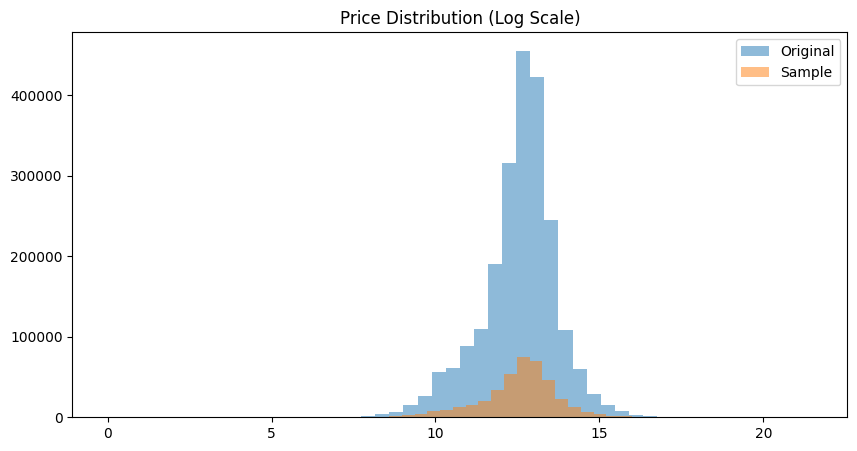

In [ ]:
# Cek representativitas: proporsi per desil harga (batas desil dihitung dari data penuh)
edges = bins.copy(); edges[0] = -np.inf; edges[-1] = np.inf
dist = pd.DataFrame({
    "Original": pd.cut(price_all, bins=edges, labels=False, include_lowest=True).value_counts(normalize=True).sort_index(),
    "Sample":   pd.cut(df['price'], bins=edges, labels=False, include_lowest=True).value_counts(normalize=True).sort_index(),
})
dist["Selisih"] = dist["Sample"] - dist["Original"]
display(dist.round(6))

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(price_all), bins=50, alpha=0.5, label='Original')
plt.hist(np.log1p(df['price']), bins=50, alpha=0.5, label='Sample')
plt.legend(); plt.title('Price Distribution (Log Scale)'); plt.show()

In [ ]:
# Pengacakan ulang baris. DIPERTAHANKAN agar split train/test identik dengan REVISI_3
# (urutan baris memengaruhi train_test_split). Tidak mengubah isi sampel.
df = df.sample(n=len(df), random_state=SEED)
print("Setelah sampling:", df.shape)

Setelah sampling: (400000, 12)


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini dilakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset sebelum dilakukan pemodelan machine learning.

Tujuan dari EDA adalah untuk memperoleh wawasan awal mengenai distribusi data, hubungan antar variabel, serta mengidentifikasi adanya outlier atau anomali yang dapat mempengaruhi performa model.

In [ ]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(400000, 12)


In [ ]:
df.head()

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
23218,51696.0,for_sale,125000.0,3.0,1.0,0.05,301365.0,Brooklyn,New York,11236.0,1056.0,2019-06-25
20731,30162.0,for_sale,450000.0,4.0,3.0,0.07,1704285.0,Evansville,Indiana,47712.0,2744.0,NaN
39555,79350.0,for_sale,74000.0,NaN,NaN,5.00,1846691.0,Tehachapi,California,93561.0,NaN,NaN
147506,25860.0,for_sale,360850.0,4.0,3.0,NaN,537421.0,Foley,Alabama,36535.0,2304.0,NaN
314215,13622.0,sold,225000.0,2.0,2.0,0.03,352821.0,Apple Valley,Minnesota,55124.0,1430.0,2021-12-23


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 400000 entries, 23218 to 121958
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   brokered_by     399186 non-null  float64
 1   status          400000 non-null  object 
 2   price           400000 non-null  float64
 3   bed             313230 non-null  float64
 4   bath            307743 non-null  float64
 5   acre_lot        341672 non-null  float64
 6   street          398034 non-null  float64
 7   city            399745 non-null  object 
 8   state           399999 non-null  object 
 9   zip_code        399946 non-null  float64
 10  house_size      297480 non-null  float64
 11  prev_sold_date  268112 non-null  object 
dtypes: float64(8), object(4)
memory usage: 39.7+ MB


In [ ]:
# Data Type Analysis
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include='object').columns.tolist())


Numerical Columns:
['brokered_by', 'price', 'bed', 'bath', 'acre_lot', 'street', 'zip_code', 'house_size']

Categorical Columns:
['status', 'city', 'state', 'prev_sold_date']


In [ ]:
# Missing value Analysis
missing = df.isnull().sum()

missing = missing[missing > 0]

missing = missing.sort_values(ascending=False)

print(missing)

prev_sold_date    131888
house_size        102520
bath               92257
bed                86770
acre_lot           58328
street              1966
brokered_by          814
city                 255
zip_code              54
state                  1
dtype: int64


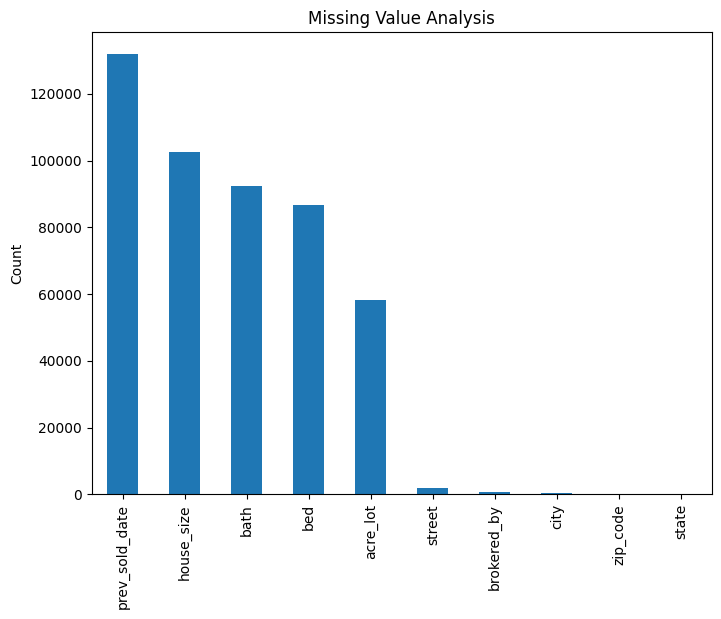

In [ ]:
# Visualisasi Missing Value
plt.figure(figsize=(8,6))

missing.plot(kind='bar')

plt.title('Missing Value Analysis')

plt.ylabel('Count')

plt.show()

In [ ]:
# Missing value precentage table
missing_percent = (
    df.isnull()
    .mean()
    * 100
).sort_values(
    ascending=False
)

missing_percent = missing_percent[
    missing_percent > 0
]

display(
    missing_percent.to_frame(
        'Missing (%)'
    )
)

,Missing (%)
prev_sold_date,32.97200
house_size,25.63000
bath,23.06425
bed,21.69250
acre_lot,14.58200
street,0.49150
brokered_by,0.20350
city,0.06375
zip_code,0.01350
state,0.00025


In [ ]:
# Duplicate Data Analysis
duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


In [ ]:
# Descriptive Statistic
df.describe().T

,count,mean,std,min,25%,50%,75%,max
brokered_by,399186.0,5.293928e+04,3.063639e+04,0.0,23859.00,52868.00,79177.75,110142.0
price,400000.0,5.228461e+05,1.272139e+06,0.0,165000.00,325000.00,550000.00,295000000.0
bed,313230.0,3.277055e+00,1.454933e+00,1.0,3.00,3.00,4.00,142.0
bath,307743.0,2.495491e+00,1.348181e+00,1.0,2.00,2.00,3.00,198.0
acre_lot,341672.0,1.383779e+01,6.696273e+02,0.0,0.15,0.26,0.98,100000.0
street,398034.0,1.013951e+06,5.841335e+05,0.0,507719.00,1016609.00,1523642.25,2001355.0
zip_code,399946.0,5.217887e+04,2.896557e+04,602.0,29615.00,48350.00,78065.00,99999.0
house_size,297480.0,2.058239e+03,4.314093e+03,100.0,1300.00,1760.00,2414.00,1095098.0


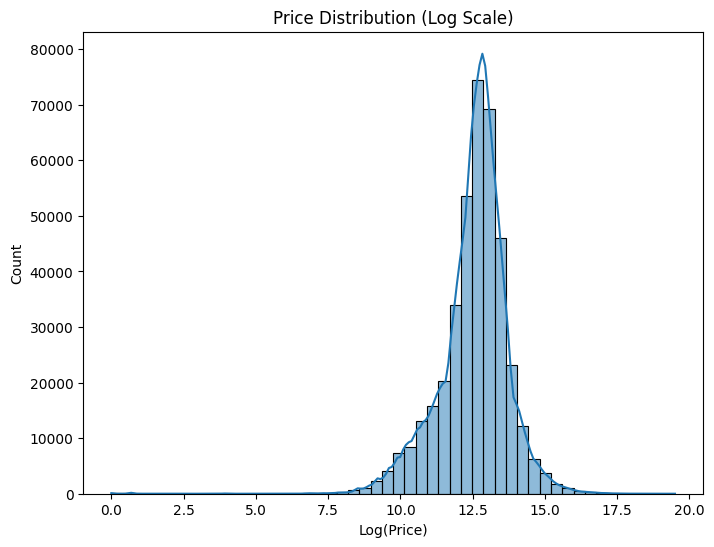

In [ ]:
# Target Distribution
plt.figure(figsize=(8,6))

sns.histplot(
    np.log1p(df['price']),
    bins=50,
    kde=True
)

plt.title('Price Distribution (Log Scale)')
plt.xlabel('Log(Price)')
plt.show()

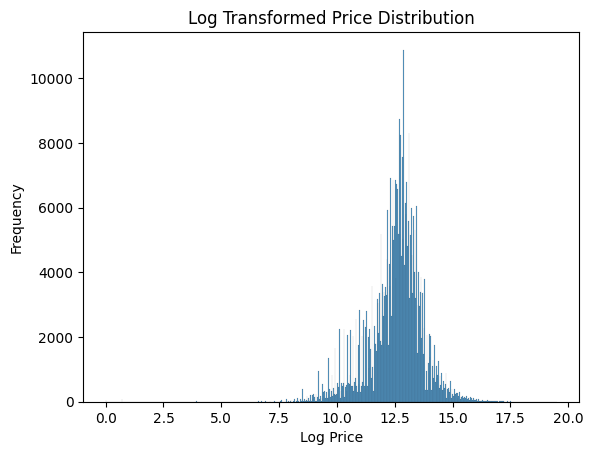

In [ ]:
# Log Transform Distibution
price_log = np.log1p(df['price'])

sns.histplot(price_log)

plt.title('Log Transformed Price Distribution')

plt.xlabel('Log Price')

plt.ylabel('Frequency')

plt.show()

INI PENTING UNTUK PAPER

Anda nanti bisa menulis:

“Logarithmic transformation was applied to reduce skewness and stabilize variance in the target variable.”

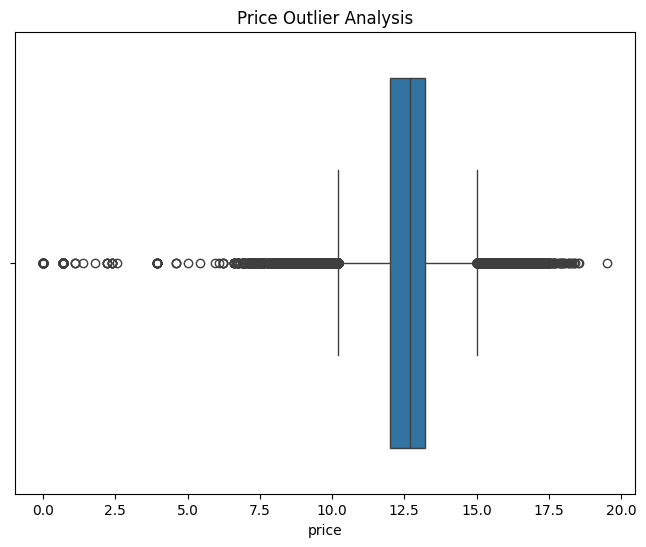

In [ ]:
# Outlier Analysis
# Boxplot Price
plt.figure(figsize=(8,6))

sns.boxplot(
    x=np.log1p(df['price'])
)

plt.title('Price Outlier Analysis')

plt.show()

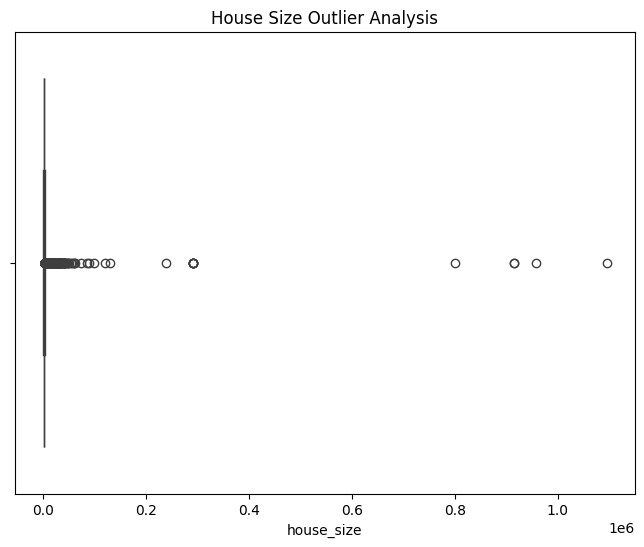

In [ ]:
# Boxplot House Size
plt.figure(figsize=(8,6))

sns.boxplot(
    x=df['house_size']
)

plt.title('House Size Outlier Analysis')

plt.show()

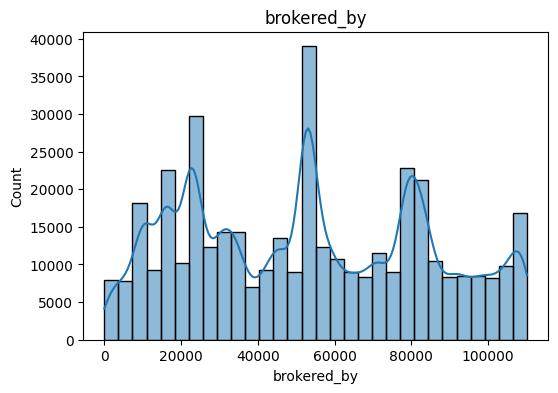

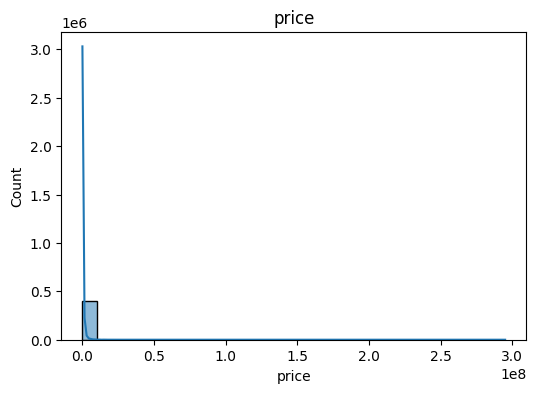

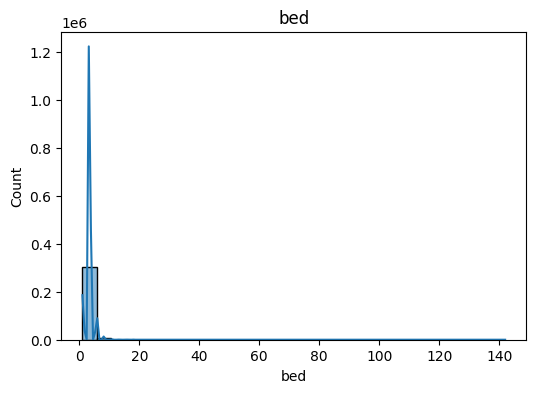

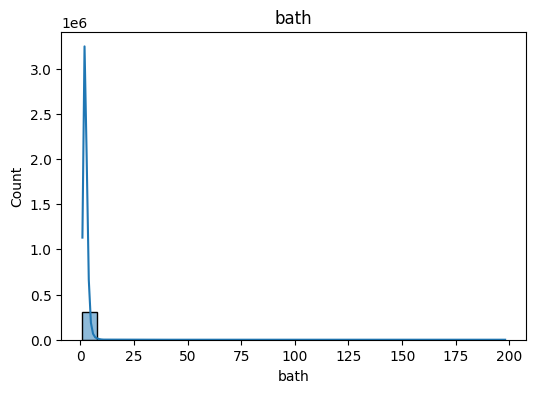

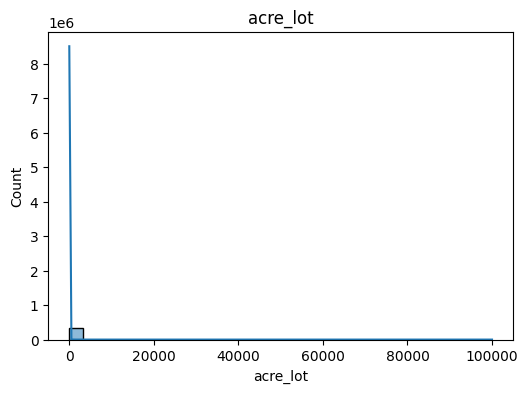

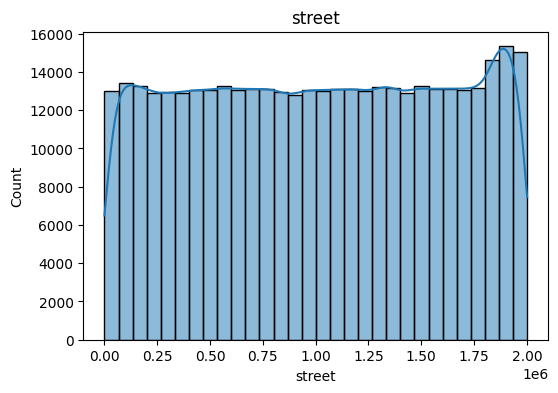

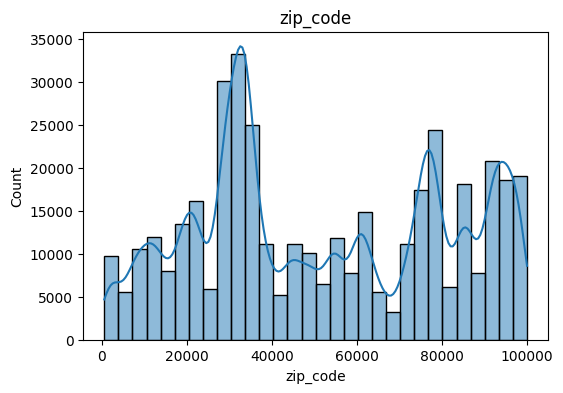

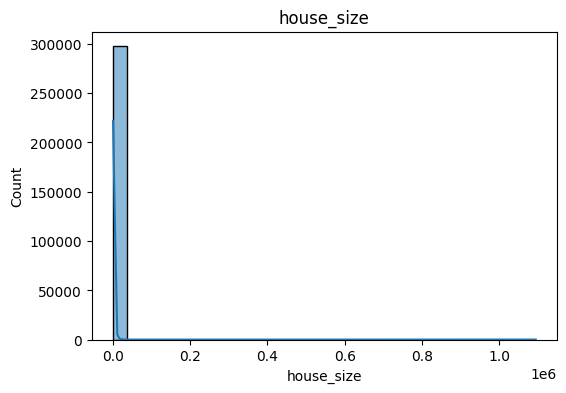

In [ ]:
# Numerical feature Distribution
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.histplot(
        df[col],
        bins=30,
        kde=True
    )

    plt.title(col)

    plt.show()

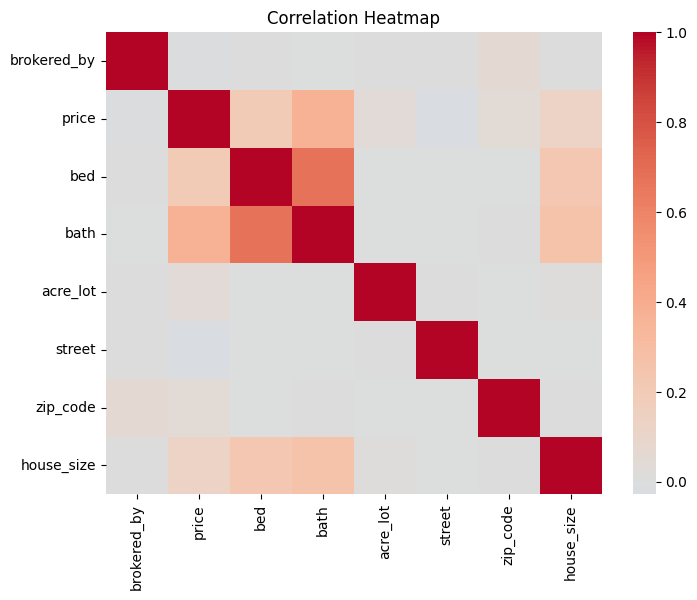

In [ ]:
# Correlation Analysis

corr_matrix = df.corr(
    numeric_only=True
)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Correlation Heatmap')

plt.show()

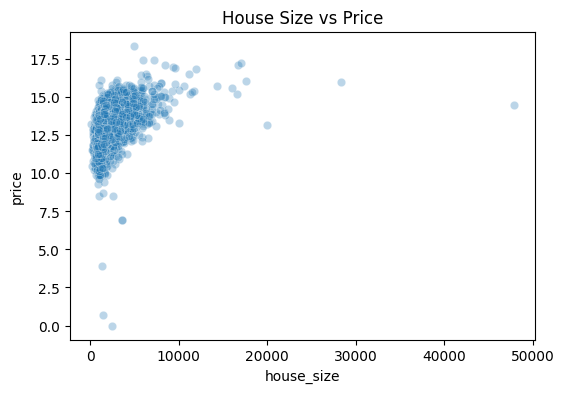

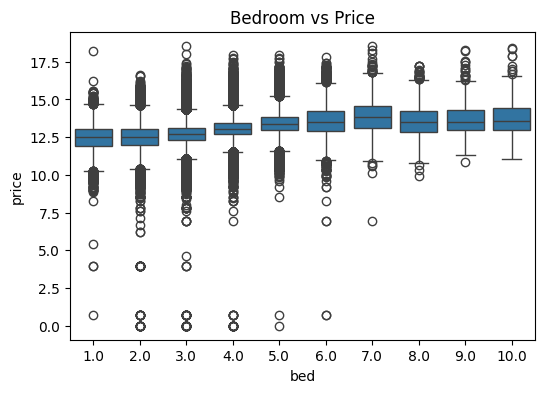

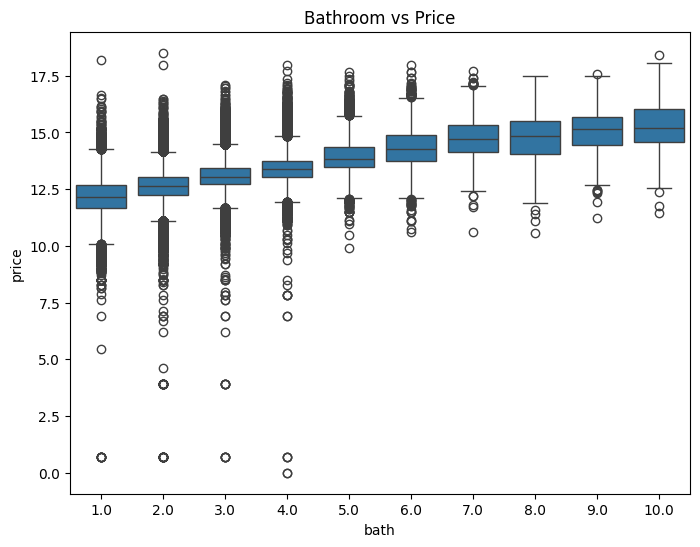

In [ ]:
# Relationship with Target
# House Size vs Price
plt.figure(figsize=(6,4))

sample_plot = df.sample(
    10000,
    random_state=42
)

sns.scatterplot(
    x=sample_plot['house_size'],
    y=np.log1p(sample_plot['price']),
    alpha=0.3
)

plt.title('House Size vs Price')

plt.show()

# Bedroom vs Price
plt.figure(figsize=(6,4))

df_bed = df[df['bed'] <= 10]

sns.boxplot(
    x=df_bed['bed'],
    y=np.log1p(df_bed['price'])
)

plt.title('Bedroom vs Price')

plt.show()

# Bathroom vs Price
plt.figure(figsize=(8,6))

df_bath = df[df['bath'] <= 10]

sns.boxplot(
    x=df_bath['bath'],
    y=np.log1p(df_bath['price'])
)

plt.title('Bathroom vs Price')

plt.show()

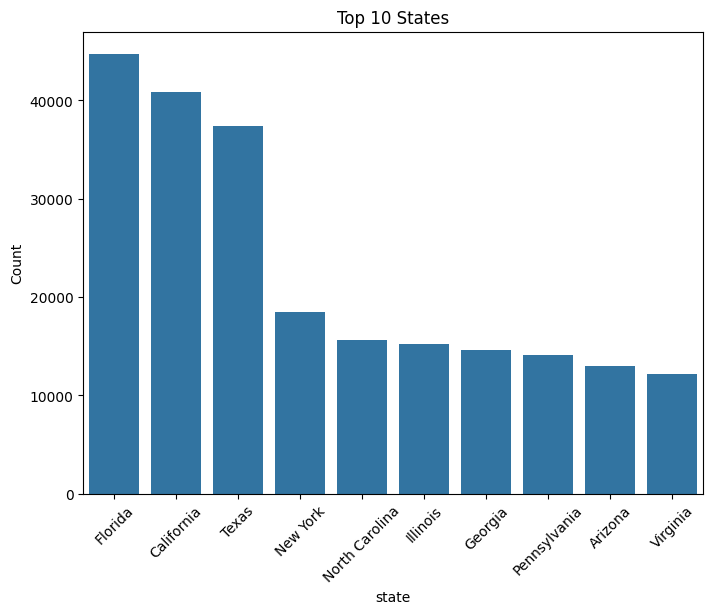

In [ ]:
# Location Analysis
# Top States
top_states = df['state'].value_counts().head(10)

plt.figure(figsize=(8,6))

sns.barplot(
    x=top_states.index,
    y=top_states.values
)

plt.xticks(rotation=45)

plt.title('Top 10 States')

plt.ylabel('Count')

plt.show()

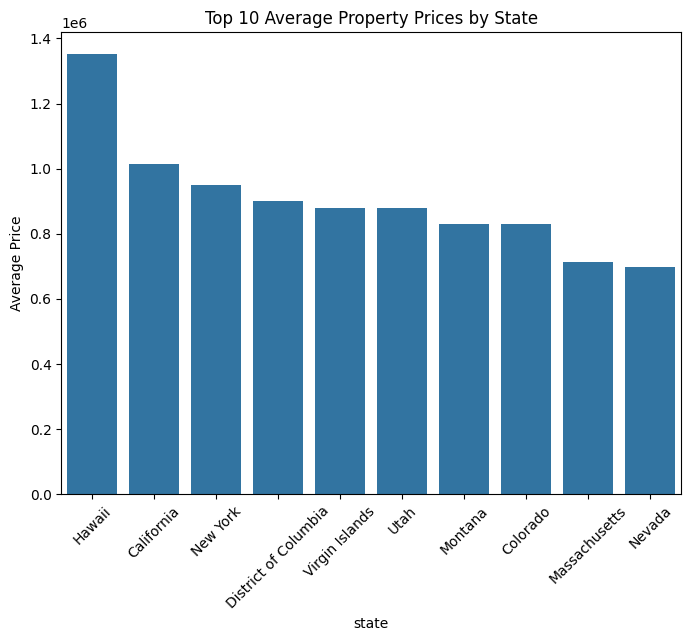

In [ ]:
# Average Price by State
avg_price_state = (
    df.groupby('state')['price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8,6))

sns.barplot(
    x=avg_price_state.index,
    y=avg_price_state.values
)

plt.xticks(rotation=45)

plt.title('Top 10 Average Property Prices by State')

plt.ylabel('Average Price')

plt.show()

# **5. Data Preprocessing**

Pada tahap ini dilakukan preprocessing untuk membersihkan dan mempersiapkan data sebelum pemodelan.

Tahapan yang dilakukan meliputi:
* Handling missing values
* Menghapus data duplikat
* Menggunakan price_log sebagai target untuk mengatasi skewness
* Encoding fitur kategorikal (city, state, status, dll)
* Menghapus fitur tidak relevan (misalnya street)
* Normalisasi/standarisasi fitur numerik (jika diperlukan)
* Pembagian data menjadi training dan testing
* Dst.

Tahap ini bertujuan **menghasilkan data yang bersih dan siap digunakan agar model dapat bekerja secara optimal**.

### Urutan yang dipakai (jawaban review: *data leakage*)
`pembersihan row-level (aturan tetap) → fitur row-wise → split → [imputasi → fitur spasial OOF → target encoding OOF → model] di dalam Pipeline`

Semua statistik yang belajar dari data (median imputasi, rata-rata target per kategori, harga per sqft per ZIP) hanya dihitung dari **training fold**.
Ambang pembersihan (harga, house_size) bersifat **tetap/ditetapkan di awal** (bukan diturunkan dari data) dan jumlah baris yang dibuang dilaporkan per langkah di bawah.

In [ ]:
# Pembersihan row-level dengan penghitungan per langkah (review: "number of records removed at each step")
n_start = len(df)
clean_log = []
def _log(step, n_b, n_a):
    clean_log.append({"Langkah": step, "Sebelum": n_b, "Sesudah": n_a, "Dibuang": n_b - n_a,
                      "% dari awal": round(100 * (n_b - n_a) / n_start, 2)})

n_b = len(df); df = df[(df['price'] >= PRICE_MIN) & (df['price'] <= PRICE_MAX)]
_log(f"price di luar [{PRICE_MIN:,}; {PRICE_MAX:,}] USD", n_b, len(df))

n_b = len(df); df = df[df['house_size'].notna()]
_log("house_size kosong (wajib: dipakai untuk price-per-sqft & base_estimate)", n_b, len(df))

n_b = len(df); df = df[(df['house_size'] >= HS_MIN) & (df['house_size'] <= HS_MAX)]
_log(f"house_size di luar [{HS_MIN:,}; {HS_MAX:,}] sqft", n_b, len(df))

n_b = len(df); df = df.drop_duplicates().reset_index(drop=True)
_log("baris duplikat persis", n_b, len(df))

clean_table = save_table("table_cleaning_steps", pd.DataFrame(clean_log))
display(clean_table)
print(f"Baris awal {n_start:,} → akhir {len(df):,} (dibuang {n_start-len(df):,} = {100*(n_start-len(df))/n_start:.2f}%)")
print("\nDistribusi status setelah pembersihan:")
print(df['status'].value_counts(dropna=False))

,Langkah,Sebelum,Sesudah,Dibuang,% dari awal
0,"price di luar [10,000; 5,000,000] USD",400000,394043,5957,1.49
1,house_size kosong (wajib: dipakai untuk price-...,394043,295390,98653,24.66
2,"house_size di luar [200; 15,000] sqft",295390,295195,195,0.05
3,baris duplikat persis,295195,295195,0,0.00


Baris awal 400,000 → akhir 295,195 (dibuang 104,805 = 26.20%)

Distribusi status setelah pembersihan:
status
for_sale          164155
sold              126624
ready_to_build      4416
Name: count, dtype: int64


# **6. Feature Engineering**

Fitur *row-wise* (hanya memakai nilai baris itu sendiri) aman dibuat sebelum split. Fitur yang memakai statistik lintas baris/target **tidak** dibuat di sini.

In [ ]:
# --- Fitur row-wise ---
df['total_rooms']      = df['bed'] + df['bath']
df['bedroom_density']  = df['bed'] / (df['house_size'] + 1)
df['bathroom_density'] = df['bath'] / (df['house_size'] + 1)
df['bath_bed_ratio']   = df['bath'] / (df['bed'] + 1)
df['room_density']     = (df['bed'] + df['bath']) / (df['house_size'] + 1)

df['prev_sold_date'] = pd.to_datetime(df['prev_sold_date'], errors='coerce')
df['years_since_sold'] = 2024 - df['prev_sold_date'].dt.year    # NaN diimputasi di dalam Pipeline
df.drop(columns=['prev_sold_date'], inplace=True)

df['price_log'] = np.log1p(df['price'])

# --- Kunci wilayah: nama kota tidak unik antar-negara bagian → gabungkan dengan state ---
city_s  = df['city'].fillna('na').astype(str).str.strip().str.lower()
state_s = df['state'].fillna('na').astype(str)
df['city_state'] = (city_s + '|' + state_s).astype(object)

# --- Identitas properti: HANYA untuk diagnostik overlap train/test (bukan fitur model) ---
_key = (df['street'].fillna(-1).astype(np.int64).astype(str) + '_' + df['zip_code'].fillna(-1).astype(np.int64).astype(str))
prop_key = pd.Series(np.where(df['street'].isna(), 'row_' + df.index.astype(str), _key).astype(str), index=df.index)

# --- status: dummy (3 kategori; tidak perlu target encoding). Simpan versi asli untuk analisis per status ---
status_all = df['status'].fillna('unknown').astype(str).copy()
status_dum = pd.get_dummies(status_all, prefix='status', dtype=np.int8)
df = pd.concat([df.drop(columns=['status', 'city']), status_dum], axis=1)

print("Feature Engineering (row-wise) selesai.", df.shape)
print("Kolom status dummy:", status_dum.columns.tolist())

Feature Engineering (row-wise) selesai. (295195, 20)
Kolom status dummy: ['status_for_sale', 'status_ready_to_build', 'status_sold']


# **7. Data Split**

Split dilakukan **sebelum** imputasi, fitur spasial berbasis target, dan target encoding.
`SPLIT_MODE="random"` mempertahankan desain REVISI_3 (80:20 acak). Diagnostik di bawah menjawab satu risiko yang belum pernah dicek: **properti yang sama (street + ZIP) muncul di train dan test** (relisting/perubahan status) sehingga skor random-split menjadi optimistis.

In [ ]:
X = df.drop(columns=["price", "price_log", "street"], errors="ignore")
y = df["price_log"]

if SPLIT_MODE == "property_group":
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    tr_idx, te_idx = next(gss.split(X, y, groups=prop_key.to_numpy()))
    X_train, X_test = X.iloc[tr_idx], X.iloc[te_idx]
    y_train, y_test = y.iloc[tr_idx], y.iloc[te_idx]
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print("SPLIT_MODE:", SPLIT_MODE)
print("X_train :", X_train.shape, "| X_test :", X_test.shape)

# --- Diagnostik: berapa baris test yang properti-nya juga ada di train? ---
train_keys = set(prop_key.loc[X_train.index])
overlap_mask = prop_key.loc[X_test.index].isin(train_keys).to_numpy()
print(f"\nBaris test dengan (street, ZIP) yang sama dengan baris train: {overlap_mask.sum():,} "
      f"({100*overlap_mask.mean():.2f}%)")
if overlap_mask.mean() > 0.02:
    print("⚠ Overlap > 2%: set SPLIT_MODE='property_group' dan jalankan ulang, atau laporkan skor terpisah (lihat bagian 10).")
else:
    print("✔ Overlap kecil (≤ 2%): random split dapat dipertahankan; tetap laporkan angka ini di Methods.")

SPLIT_MODE: random
X_train : (236156, 17) | X_test : (59039, 17)

Baris test dengan (street, ZIP) yang sama dengan baris train: 1,728 (2.93%)
⚠ Overlap > 2%: set SPLIT_MODE='property_group' dan jalankan ulang, atau laporkan skor terpisah (lihat bagian 10).


# **8. Pipeline Leakage-Resistant**

`Imputasi (+ flag missing) → Fitur spasial (OOF) → Target encoding (OOF) → Isi sisa NaN (zip_code kosong) → Model`

Semua langkah belajar **hanya** dari data training pada setiap fold (CV, Optuna, geo-CV, bootstrap-CV).

**Rumus (untuk Methods, review "exact smoothing formula"):**

- Harga per sqft baris *i*: `pps_i = price_i / (house_size_i + 1)` (USD/sqft).
- Estimasi level *L* (state, ZIP3, ZIP, kota): `est_L = (n_L · median_L + m · est_parent) / (n_L + m)`, dengan `m = 10` (`smoothing`), `n_L` = jumlah baris training pada grup itu.
- Rantai *back-off*: `global → state → ZIP3 → ZIP` dan `state → kota`. **ZIP yang tidak pernah dilihat** otomatis memakai estimasi ZIP3-nya, lalu state, lalu median global.
- `area_sqft_price = est_ZIP`, `base_estimate = area_sqft_price × house_size`.
- Pada data *training*, setiap baris mendapat nilai dari fold lain (5-fold OOF); pada validation/test dipakai peta dari seluruh data training. Opsi `group_oof=True` membuat fold OOF **per ZIP** (meniru ZIP yang belum pernah dilihat).
- Target encoding kategori (`state`, `city_state`, `brokered_by`): `enc = (n·mean_log_price + m·prior)/(n+m)`, `m = 10`, kategori baru → `prior` (rata-rata log-harga training fold). 5-fold OOF, `random_state=42`.

In [ ]:
def _non_numeric_cols(X):
    return [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]


class ZipMedianImputer(TransformerMixin, BaseEstimator):
    """Imputasi median per ZIP (fallback median global) + flag missing. Belajar hanya dari data fit."""
    def __init__(self, num_cols=("house_size", "bed", "bath", "acre_lot", "years_since_sold"),
                 flag_cols=("bed", "bath", "acre_lot", "years_since_sold")):
        self.num_cols = num_cols
        self.flag_cols = flag_cols

    def fit(self, X, y=None):
        has_zip = "zip_code" in X.columns
        self.zip_medians_, self.global_medians_ = {}, {}
        for c in self.num_cols:
            if c in X.columns:
                self.global_medians_[c] = float(X[c].median())
                if has_zip:
                    self.zip_medians_[c] = X.groupby("zip_code")[c].median()
        self.cat_modes_ = {}
        for c in _non_numeric_cols(X):
            m = X[c].mode(dropna=True)
            self.cat_modes_[c] = m.iloc[0] if len(m) else "__MISSING__"
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.flag_cols:                       # informasi "nilai ini kosong" tidak hilang
            if c in X.columns:
                X[c + "_na"] = X[c].isna().astype(np.int8)
        for c, med in self.zip_medians_.items():
            X[c] = X[c].fillna(X["zip_code"].map(med))
        for c, med in self.global_medians_.items():
            X[c] = X[c].fillna(med)
        for c, mode in self.cat_modes_.items():
            if c in X.columns:
                X[c] = X[c].fillna(mode)
        for c in ["total_rooms", "bedroom_density", "bathroom_density", "bath_bed_ratio", "room_density"]:
            if c in X.columns:
                X[c] = X[c].replace([np.inf, -np.inf], np.nan).fillna(0)
        return X


class HierSpatialFeatures(TransformerMixin, BaseEstimator):
    """Fitur spasial berbasis target (harga/sqft) dengan shrinkage hierarkis & OOF ketat.

    hierarchical=False -> hanya ZIP, fallback median global (= desain REVISI_3)
    oof=False          -> varian LEAKY (in-sample), HANYA untuk ablation
    group_oof=True     -> fold OOF per ZIP (meniru ZIP yang belum pernah dilihat)
    """
    def __init__(self, hierarchical=True, oof=True, group_oof=False, n_splits=5, smoothing=10, random_state=42):
        self.hierarchical = hierarchical
        self.oof = oof
        self.group_oof = group_oof
        self.n_splits = n_splits
        self.smoothing = smoothing
        self.random_state = random_state

    @staticmethod
    def _keys(X):
        z = X["zip_code"].astype(float)
        return {"zip": z, "zip3": np.floor(z / 100.0), "city": X["city_state"], "state": X["state"]}

    def _shrink(self, key, pps, parent):
        d = pd.DataFrame({"k": np.asarray(key), "v": pps, "p": parent})
        g = d.groupby("k")
        n, med, par = g["v"].size(), g["v"].median(), g["p"].mean()
        return (n * med + self.smoothing * par) / (n + self.smoothing)

    def _fit_maps(self, X, y):
        pps = np.expm1(np.asarray(y, dtype=float)) / (X["house_size"].to_numpy(dtype=float) + 1.0)
        g0 = float(np.median(pps))
        k = self._keys(X)
        n = len(pps)
        if not self.hierarchical:
            return {"g0": g0, "zip": self._shrink(k["zip"], pps, np.full(n, g0))}
        est_state = self._shrink(k["state"], pps, np.full(n, g0))
        row_state = k["state"].map(est_state).astype(float).fillna(g0).to_numpy()
        est_zip3 = self._shrink(k["zip3"], pps, row_state)
        row_zip3 = k["zip3"].map(est_zip3).astype(float).to_numpy()
        row_zip3 = np.where(np.isnan(row_zip3), row_state, row_zip3)
        return {"g0": g0, "state": est_state, "zip3": est_zip3,
                "zip": self._shrink(k["zip"], pps, row_zip3),
                "city": self._shrink(k["city"], pps, row_state)}

    def _apply(self, X, maps):
        k, g0 = self._keys(X), maps["g0"]
        if not self.hierarchical:
            z = k["zip"].map(maps["zip"]).astype(float).fillna(g0).to_numpy()
            return None, None, z, None
        s = k["state"].map(maps["state"]).astype(float).fillna(g0).to_numpy()
        z3 = k["zip3"].map(maps["zip3"]).astype(float).to_numpy();  z3 = np.where(np.isnan(z3), s, z3)
        z = k["zip"].map(maps["zip"]).astype(float).to_numpy();      z = np.where(np.isnan(z), z3, z)
        c = k["city"].map(maps["city"]).astype(float).to_numpy();    c = np.where(np.isnan(c), s, c)
        return s, z3, z, c

    def _assemble(self, X, parts):
        s, z3, z, c = parts
        out = X.copy()
        if self.hierarchical:
            out["pps_state"], out["pps_zip3"], out["pps_city"] = s, z3, c
        out["area_sqft_price"] = z
        out["base_estimate"] = z * out["house_size"].to_numpy(dtype=float)
        return out

    def fit(self, X, y):
        self.maps_ = self._fit_maps(X, y)
        return self

    def transform(self, X):
        return self._assemble(X, self._apply(X, self.maps_))

    def fit_transform(self, X, y=None, **fit_params):
        if y is None:
            raise ValueError("y diperlukan untuk fitur spasial berbasis target")
        y_arr = np.asarray(y, dtype=float)
        self.fit(X, y_arr)                               # peta penuh -> dipakai untuk data baru (validation/test)
        if not self.oof:                                 # varian LEAKY (in-sample)
            return self.transform(X)
        if self.group_oof:
            groups = X["zip_code"].fillna(-1).to_numpy()
            k = max(2, min(self.n_splits, len(np.unique(groups))))
            splits = GroupKFold(n_splits=k).split(X, groups=groups)
        else:
            splits = KFold(n_splits=self.n_splits, shuffle=True, random_state=self.random_state).split(X)
        n = len(X)
        bufs = [np.full(n, np.nan) if (self.hierarchical or i == 2) else None for i in range(4)]
        for fit_idx, hold_idx in splits:
            maps = self._fit_maps(X.iloc[fit_idx], y_arr[fit_idx])
            for b, p in zip(bufs, self._apply(X.iloc[hold_idx], maps)):
                if b is not None:
                    b[hold_idx] = p
        return self._assemble(X, bufs)


class OOFTargetEncoder(TransformerMixin, BaseEstimator):
    """Target encoding (rata-rata log-harga) dengan smoothing; OOF ketat pada data training."""
    def __init__(self, cols=("state", "city_state", "brokered_by"), oof=True, n_splits=5, smoothing=10, random_state=42):
        self.cols = cols
        self.oof = oof
        self.n_splits = n_splits
        self.smoothing = smoothing
        self.random_state = random_state

    def _stats(self, keys, y, prior):
        g = pd.DataFrame({"k": keys, "v": y}).groupby("k")["v"]
        n, mean = g.size(), g.mean()
        return (n * mean + self.smoothing * prior) / (n + self.smoothing)

    @staticmethod
    def _key(X, c):
        return X[c].astype(str).to_numpy()

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.prior_ = float(y.mean())
        self.cols_ = [c for c in self.cols if c in X.columns]
        self.maps_ = {c: self._stats(self._key(X, c), y, self.prior_) for c in self.cols_}
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.cols_:
            X[c] = pd.Series(self._key(X, c)).map(self.maps_[c]).astype(float).fillna(self.prior_).to_numpy()
        return X

    def fit_transform(self, X, y=None, **fit_params):
        if y is None:
            raise ValueError("y diperlukan untuk target encoding")
        y_arr = np.asarray(y, dtype=float)
        self.fit(X, y_arr)
        if not self.oof:                                 # varian LEAKY (in-sample)
            return self.transform(X)
        keys = {c: self._key(X, c) for c in self.cols_}
        bufs = {c: np.full(len(X), np.nan) for c in self.cols_}
        kf = KFold(n_splits=self.n_splits, shuffle=True, random_state=self.random_state)
        for fit_idx, hold_idx in kf.split(X):
            yf = y_arr[fit_idx]
            prior = float(yf.mean())
            for c in self.cols_:
                mp = self._stats(keys[c][fit_idx], yf, prior)
                bufs[c][hold_idx] = pd.Series(keys[c][hold_idx]).map(mp).astype(float).fillna(prior).to_numpy()
        out = X.copy()
        for c in self.cols_:
            out[c] = bufs[c]
        return out


class FillRemainingNaN(TransformerMixin, BaseEstimator):
    """Sisa NaN (praktis hanya zip_code yang kosong, ±0,01% baris) -> -1 ('ZIP tidak diketahui').
    Dilakukan SETELAH fitur spasial agar ZIP kosong tetap memakai back-off ke state/global."""
    def fit(self, X, y=None):
        self.fitted_ = True          # agar check_is_fitted sklearn lolos bila Pipeline tanpa model dipakai
        return self
    def transform(self, X):
        return X.fillna(-1)


CAT_COLS = ["state", "city_state", "brokered_by"]

def make_pipeline(model, spatial="hier", oof=True, group_oof=False):
    """spatial: 'hier' (usulan) | 'zip' (REVISI_3: ZIP saja) | 'none' (tanpa fitur spasial)."""
    steps = [("imputer", ZipMedianImputer())]
    if spatial != "none":
        steps.append(("spatial", HierSpatialFeatures(hierarchical=(spatial == "hier"), oof=oof,
                                                    group_oof=group_oof, n_splits=5, smoothing=10, random_state=SEED)))
    steps.append(("target_encoder", OOFTargetEncoder(cols=tuple(CAT_COLS), oof=oof, n_splits=5, smoothing=10, random_state=SEED)))
    steps.append(("fill_nan", FillRemainingNaN()))
    steps.append(("model", model))
    return Pipeline(steps)

def transform_until_model(pipe, X):
    """Terapkan semua langkah pra-pemrosesan (yang sudah fit) — dipakai untuk SHAP."""
    Xt = X
    for _, step in pipe.steps[:-1]:
        Xt = step.transform(Xt)
    return Xt

## 8.1 Uji kebocoran (harus lulus sebelum tuning)

1. **Uji OOF**: pada ZIP yang hanya punya 1 baris training, fitur varian *leaky* menyalin harga baris itu sendiri; fitur OOF tidak boleh.
2. **Tanpa NaN** setelah seluruh transformasi dan kolom `train` = kolom `test`.

In [ ]:
# --- Uji 1: OOF vs in-sample pada baris yang ZIP-nya hanya muncul sekali di training ---
Xs = X_train.sample(n=min(20000, len(X_train)), random_state=SEED)
ys = y_train.loc[Xs.index]
Xi = ZipMedianImputer().fit(Xs).transform(Xs)

oof_f   = HierSpatialFeatures(hierarchical=False, oof=True ).fit_transform(Xi, ys)["area_sqft_price"].to_numpy()
leaky_f = HierSpatialFeatures(hierarchical=False, oof=False).fit_transform(Xi, ys)["area_sqft_price"].to_numpy()
own_pps = np.expm1(ys.to_numpy()) / (Xi["house_size"].to_numpy() + 1)

single = Xi["zip_code"].map(Xi["zip_code"].value_counts()).to_numpy() == 1
if single.sum() >= 20:
    c_oof, c_leaky = (np.corrcoef(f[single], own_pps[single])[0, 1] for f in (oof_f, leaky_f))
    print(f"Baris dengan ZIP singleton: {single.sum()}")
    print(f"  korelasi fitur OOF   vs harga sendiri : {c_oof:.3f}   (harus rendah)")
    print(f"  korelasi fitur LEAKY vs harga sendiri : {c_leaky:.3f}   (tinggi = bukti kebocoran jika tidak di-OOF)")
    assert c_oof < c_leaky, "Fitur OOF tidak lebih rendah dari leaky -> periksa implementasi"
else:
    print("ZIP singleton terlalu sedikit pada sampel ini; uji 1 dilewati.")

# --- Uji 2: pipeline utuh pada sampel kecil (Ridge hanya sebagai model uji) ---
Xc, yc = X_train.iloc[:2000], y_train.iloc[:2000]
test_pipe = make_pipeline(Ridge()).fit(Xc, yc)
Xt_chk = transform_until_model(test_pipe, X_test.iloc[:500])
assert np.isfinite(test_pipe.predict(X_test.iloc[:500])).all(), "Prediksi non-finite"
assert Xt_chk.isna().sum().sum() == 0, f"NaN tersisa: {Xt_chk.columns[Xt_chk.isna().any()].tolist()}"
assert Xt_chk.select_dtypes(exclude=[np.number]).shape[1] == 0, "Masih ada kolom non-numerik"
print("\n✔ Uji 2 lulus. Kolom akhir yang masuk model:", Xt_chk.shape[1])
print(list(Xt_chk.columns))

Baris dengan ZIP singleton: 4525
  korelasi fitur OOF   vs harga sendiri : -0.024   (harus rendah)
  korelasi fitur LEAKY vs harga sendiri : 1.000   (tinggi = bukti kebocoran jika tidak di-OOF)

✔ Uji 2 lulus. Kolom akhir yang masuk model: 26
['brokered_by', 'bed', 'bath', 'acre_lot', 'state', 'zip_code', 'house_size', 'total_rooms', 'bedroom_density', 'bathroom_density', 'bath_bed_ratio', 'room_density', 'years_since_sold', 'city_state', 'status_for_sale', 'status_ready_to_build', 'status_sold', 'bed_na', 'bath_na', 'acre_lot_na', 'years_since_sold_na', 'pps_state', 'pps_zip3', 'pps_city', 'area_sqft_price', 'base_estimate']


## 8.2 Metrik evaluasi

Semua model dinilai dengan fungsi yang sama.
- `*_log`: skala log-harga (target model; **bukan** dolar). `*_USD`: setelah `expm1`.
- `MAPE`/`MdAPE`: aman karena harga ≥ 10.000 USD. `MdAE`: ringkasan kesalahan yang tidak terdistorsi harga mewah.
- `COD` (coefficient of dispersion, IAAO): `100 · mean(|r − median(r)|) / median(r)` dengan rasio `r = prediksi/aktual` — **pastikan definisi ini sama dengan yang dipakai di manuskrip**.
- `PPE10/PPE20`: % properti dengan |kesalahan relatif| ≤ 10% / 20% (ukuran praktis AVM).

In [ ]:
HIGHER_BETTER = ["R2_log", "R2_USD", "PPE10_%", "PPE20_%"]

def full_metrics(name, y_true_log, y_pred_log):
    yt = np.expm1(np.asarray(y_true_log, dtype=float))
    yp = np.expm1(np.asarray(y_pred_log, dtype=float))
    ae = np.abs(yp - yt)
    ape = ae / yt
    ratio = yp / yt
    cod = 100 * np.mean(np.abs(ratio - np.median(ratio))) / np.median(ratio)
    return {
        "Model": name,
        "R2_log": r2_score(y_true_log, y_pred_log),
        "MAE_log": mean_absolute_error(y_true_log, y_pred_log),
        "RMSE_log": float(np.sqrt(mean_squared_error(y_true_log, y_pred_log))),
        "R2_USD": r2_score(yt, yp),
        "RMSE_USD": float(np.sqrt(mean_squared_error(yt, yp))),
        "MAE_USD": mean_absolute_error(yt, yp),
        "MdAE_USD": float(np.median(ae)),
        "MAPE_%": 100 * float(ape.mean()),
        "MdAPE_%": 100 * float(np.median(ape)),
        "COD": float(cod),
        "PPE10_%": 100 * float((ape <= 0.10).mean()),
        "PPE20_%": 100 * float((ape <= 0.20).mean()),
    }

# **9. Equal-Budget Optuna**

Setiap model mendapat **jumlah trial yang sama** (`N_TRIALS`, = 30 pada run penuh — *teks manuskrip harus menulis 30, bukan 15*), objective yang sama (R² log-harga, 3-fold CV acak pada 25% `X_train`, `maximize`), sampler `TPESampler(seed=42)`, dan Pipeline yang sama.
Koreksi ruang pencarian dibanding REVISI_3: LightGBM sebelumnya memakai `num_leaves` tetap 31 (sehingga `max_depth` 4–12 tidak berefek) dan `subsample` tanpa `subsample_freq` (tidak aktif); learning rate kini skala-log; regularisasi ditambahkan untuk semua model; batas atas `max_depth`/`n_estimators` yang sebelumnya selalu tercapai dilonggarkan.

Studi disimpan ke SQLite → jika Colab terputus cukup *Run all* lagi.

In [ ]:
kf_search = KFold(n_splits=3, shuffle=True, random_state=SEED)
X_search = X_train.sample(frac=SEARCH_FRAC, random_state=SEED)
y_search = y_train.loc[X_search.index]
print("Baris untuk tuning:", len(X_search))

def build_rf(trial):
    return RandomForestRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 250),
        max_depth=trial.suggest_int("max_depth", 12, 28),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 12),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 8),
        max_features=trial.suggest_float("max_features", 0.4, 1.0),
        random_state=SEED, n_jobs=1)

def build_lgbm(trial):
    return LGBMRegressor(
        n_estimators=trial.suggest_int("n_estimators", 300, 1500),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 60),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 1.0, log=True),
        random_state=SEED, n_jobs=1, verbosity=-1)

def build_cb(trial):
    return CatBoostRegressor(
        iterations=trial.suggest_int("iterations", 500, 1500),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        depth=trial.suggest_int("depth", 4, 10),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
        verbose=0, random_state=SEED, thread_count=1)

def build_xgb(trial):
    return XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 300, 1500),
        max_depth=trial.suggest_int("max_depth", 4, 12),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 1.0, log=True),
        random_state=SEED, tree_method="hist", n_jobs=1)

BEST_PARAMS, STUDIES = {}, {}

def optuna_search(model_builder, name):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                study_name=f"{name}_{STUDY_TAG}", storage=STORAGE, load_if_exists=True)
    done = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
    todo = N_TRIALS - done
    print(f"[{name}] trial selesai: {done} | sisa: {max(todo, 0)}")

    def objective(trial):
        pipe = make_pipeline(model_builder(trial))
        return cross_val_score(pipe, X_search, y_search, cv=kf_search, scoring="r2", n_jobs=-1).mean()

    if todo > 0:
        study.optimize(objective, n_trials=todo, show_progress_bar=False)
    print(f"[{name}] best CV R2 (tuning, 25% data): {study.best_value:.4f}")
    print(f"[{name}] best params: {study.best_params}")
    BEST_PARAMS[name] = study.best_params
    STUDIES[name] = study
    json.dump(BEST_PARAMS, open(os.path.join(OUT_DIR, "best_params.json"), "w"), indent=2)
    study.trials_dataframe().to_csv(os.path.join(OUT_DIR, f"optuna_trials_{name.replace(' ', '_')}.csv"), index=False)
    return study

Baris untuk tuning: 59039


In [ ]:
t0 = time.time()
optuna_search(build_lgbm, "LightGBM")
optuna_search(build_xgb,  "XGBoost")
optuna_search(build_cb,   "CatBoost")
optuna_search(build_rf,   "Random Forest")      # paling lambat (±2 jam pada run REVISI_3); terakhir agar model lain tersimpan dulu
print(f"\nTotal waktu tuning sesi ini: {(time.time()-t0)/60:.1f} menit")

tuning_table = pd.DataFrame([{"Model": n, "Best CV R2 (log, 25% data)": s.best_value, "N trial": len(s.trials),
                              **{f"param:{k}": v for k, v in s.best_params.items()}} for n, s in STUDIES.items()])
save_table("table_best_hyperparameters", tuning_table)
display(tuning_table.T)

[I 2026-10-27 06:38:50,816] A new study created in RDB with name: LightGBM_v4


[LightGBM] trial selesai: 0 | sisa: 30


[I 2026-10-27 06:39:34,461] Trial 0 finished with value: 0.7761686133836719 and parameters: {'n_estimators': 749, 'learning_rate': 0.13125830316209655, 'num_leaves': 118, 'min_child_samples': 38, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_lambda': 0.014936568554617643, 'reg_alpha': 0.39676050770529875}. Best is trial 0 with value: 0.7761686133836719.
[I 2026-10-27 06:39:54,621] Trial 1 finished with value: 0.7943883016883815 and parameters: {'n_estimators': 1021, 'learning_rate': 0.06803900745073706, 'num_leaves': 15, 'min_child_samples': 59, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_lambda': 0.035113563139704075, 'reg_alpha': 0.0035498788321965025}. Best is trial 1 with value: 0.7943883016883815.
[I 2026-10-27 06:40:14,636] Trial 2 finished with value: 0.7960755059045064 and parameters: {'n_estimators': 665, 'learning_rate': 0.04141536110538596, 'num_leaves': 50, 'min_child_samples': 21, 'subsample': 0.8447411578889

[LightGBM] best CV R2 (tuning, 25% data): 0.7974
[LightGBM] best params: {'n_estimators': 1004, 'learning_rate': 0.03884247905950703, 'num_leaves': 79, 'min_child_samples': 14, 'subsample': 0.895078830362237, 'colsample_bytree': 0.6031315065552628, 'reg_lambda': 0.2123679468901839, 'reg_alpha': 0.0037561829611147063}
[XGBoost] trial selesai: 0 | sisa: 30


[I 2026-10-27 06:53:42,334] Trial 0 finished with value: 0.784885548558262 and parameters: {'n_estimators': 749, 'max_depth': 12, 'learning_rate': 0.07259248719561363, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 4, 'reg_lambda': 0.014936568554617643, 'reg_alpha': 0.39676050770529875}. Best is trial 0 with value: 0.784885548558262.
[I 2026-10-27 06:55:43,077] Trial 1 finished with value: 0.7903566948838869 and parameters: {'n_estimators': 1021, 'max_depth': 10, 'learning_rate': 0.010573268083515799, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9329770563201687, 'min_child_weight': 5, 'reg_lambda': 0.035113563139704075, 'reg_alpha': 0.0035498788321965025}. Best is trial 1 with value: 0.7903566948838869.
[I 2026-10-27 06:56:26,331] Trial 2 finished with value: 0.7957707497603197 and parameters: {'n_estimators': 665, 'max_depth': 8, 'learning_rate': 0.032211189352044464, 'subsample': 0.7164916560792167, 'colsample_bytree': 0.844741

[XGBoost] best CV R2 (tuning, 25% data): 0.7962
[XGBoost] best params: {'n_estimators': 1011, 'max_depth': 8, 'learning_rate': 0.023936155479847846, 'subsample': 0.756407584977042, 'colsample_bytree': 0.9815221834248236, 'min_child_weight': 5, 'reg_lambda': 0.08792659215220651, 'reg_alpha': 0.0038955048066202}
[CatBoost] trial selesai: 0 | sisa: 30


[I 2026-10-27 07:21:11,327] Trial 0 finished with value: 0.7944843233806546 and parameters: {'iterations': 874, 'learning_rate': 0.1358198535217987, 'depth': 9, 'l2_leaf_reg': 3.968793330444372}. Best is trial 0 with value: 0.7944843233806546.
[I 2026-10-27 07:21:29,105] Trial 1 finished with value: 0.7740289604176628 and parameters: {'iterations': 656, 'learning_rate': 0.027386388058464273, 'depth': 4, 'l2_leaf_reg': 7.348118405270449}. Best is trial 0 with value: 0.7944843233806546.
[I 2026-10-27 07:21:56,771] Trial 2 finished with value: 0.7904782221864952 and parameters: {'iterations': 1101, 'learning_rate': 0.08329844231669226, 'depth': 4, 'l2_leaf_reg': 9.330606024425668}. Best is trial 0 with value: 0.7944843233806546.
[I 2026-10-27 07:22:36,358] Trial 3 finished with value: 0.7893648638609977 and parameters: {'iterations': 1333, 'learning_rate': 0.030678895924589226, 'depth': 5, 'l2_leaf_reg': 1.5254729458052607}. Best is trial 0 with value: 0.7944843233806546.
[I 2026-10-27 07

[CatBoost] best CV R2 (tuning, 25% data): 0.7975
[CatBoost] best params: {'iterations': 1002, 'learning_rate': 0.04030089378011933, 'depth': 10, 'l2_leaf_reg': 1.8211762712186754}
[Random Forest] trial selesai: 0 | sisa: 30


[I 2026-10-27 08:19:50,082] Trial 0 finished with value: 0.7774665785189147 and parameters: {'n_estimators': 156, 'max_depth': 28, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.4936111842654619}. Best is trial 0 with value: 0.7774665785189147.
[I 2026-10-27 08:22:35,220] Trial 1 finished with value: 0.7690696558198519 and parameters: {'n_estimators': 123, 'max_depth': 12, 'min_samples_split': 11, 'min_samples_leaf': 5, 'max_features': 0.8248435466776274}. Best is trial 0 with value: 0.7774665785189147.
[I 2026-10-27 08:24:46,287] Trial 2 finished with value: 0.777497663270074 and parameters: {'n_estimators': 103, 'max_depth': 28, 'min_samples_split': 11, 'min_samples_leaf': 2, 'max_features': 0.5090949803242604}. Best is trial 2 with value: 0.777497663270074.
[I 2026-10-27 08:27:11,454] Trial 3 finished with value: 0.777125109142931 and parameters: {'n_estimators': 127, 'max_depth': 17, 'min_samples_split': 7, 'min_samples_leaf': 4, 'max_features': 0.574737484118825

[Random Forest] best CV R2 (tuning, 25% data): 0.7784
[Random Forest] best params: {'n_estimators': 124, 'max_depth': 26, 'min_samples_split': 11, 'min_samples_leaf': 3, 'max_features': 0.45399749995933647}

Total waktu tuning sesi ini: 181.1 menit


,0,1,2,3
Model,LightGBM,XGBoost,CatBoost,Random Forest
"Best CV R2 (log, 25% data)",0.797422,0.796182,0.797527,0.778428
N trial,30,30,30,30
param:n_estimators,1004.0,1011.0,NaN,124.0
param:learning_rate,0.038842,0.023936,0.040301,NaN
param:num_leaves,79.0,NaN,NaN,NaN
param:min_child_samples,14.0,NaN,NaN,NaN
param:subsample,0.895079,0.756408,NaN,NaN
param:colsample_bytree,0.603132,0.981522,NaN,NaN
param:reg_lambda,0.212368,0.087927,NaN,NaN


# **10. Model Akhir & Evaluasi Random Test**

Setiap model dilatih ulang pada **seluruh** `X_train`; `X_test` baru disentuh di sini (sekali).

In [ ]:
def rf_from_params(p):   return RandomForestRegressor(**p, random_state=SEED, n_jobs=-1)
def lgbm_from_params(p): return LGBMRegressor(**p, subsample_freq=1, random_state=SEED, n_jobs=-1, verbosity=-1)
def cb_from_params(p):   return CatBoostRegressor(**p, verbose=0, random_state=SEED, thread_count=-1)
def xgb_from_params(p):  return XGBRegressor(**p, random_state=SEED, tree_method="hist", n_jobs=-1)
FROM_PARAMS = {"Random Forest": rf_from_params, "LightGBM": lgbm_from_params,
               "CatBoost": cb_from_params, "XGBoost": xgb_from_params}

FINAL, PRED, FIT_SECONDS = {}, {}, {}
for name, fn in FROM_PARAMS.items():
    t0 = time.time()
    FINAL[name] = make_pipeline(fn(BEST_PARAMS[name])).fit(X_train, y_train)
    PRED[name] = FINAL[name].predict(X_test)
    FIT_SECONDS[name] = time.time() - t0
    print(f"{name:14s} selesai ({FIT_SECONDS[name]/60:.1f} menit) | R2_log test = {r2_score(y_test, PRED[name]):.4f}")

Random Forest  selesai (4.8 menit) | R2_log test = 0.8274
LightGBM       selesai (0.7 menit) | R2_log test = 0.8389
CatBoost       selesai (2.9 menit) | R2_log test = 0.8376
XGBoost        selesai (0.9 menit) | R2_log test = 0.8376


In [ ]:
if RUN_STACKING:
    t0 = time.time()
    stack_final = StackingRegressor(
        estimators=[("xgb",  make_pipeline(xgb_from_params(BEST_PARAMS["XGBoost"]))),
                    ("cat",  make_pipeline(cb_from_params(BEST_PARAMS["CatBoost"]))),
                    ("lgbm", make_pipeline(lgbm_from_params(BEST_PARAMS["LightGBM"])))],
        final_estimator=Ridge(alpha=1.0), passthrough=False, n_jobs=-1, cv=3)
    stack_final.fit(X_train, y_train)
    PRED["Stacking"] = stack_final.predict(X_test)
    print(f"Stacking selesai ({(time.time()-t0)/60:.1f} menit) | R2_log test = {r2_score(y_test, PRED['Stacking']):.4f}")
else:
    print("Stacking dilewati (RUN_STACKING=False).")

Stacking selesai (15.6 menit) | R2_log test = 0.8396


In [ ]:
# Tabel utama (random test) — satu-satunya sumber angka untuk Table 2 manuskrip
results_main = pd.DataFrame([full_metrics(n, y_test, p) for n, p in PRED.items()])
results_main = results_main.sort_values("R2_USD", ascending=False).reset_index(drop=True)
save_table("table_main_random_test", results_main)
display(results_main.round(4))

pd.DataFrame({"y_test_log": y_test.to_numpy(), **{f"pred_{n}": p for n, p in PRED.items()}},
             index=X_test.index).to_csv(os.path.join(OUT_DIR, "predictions_test.csv"))

# Kalimat peringkat dibuat OTOMATIS dari tabel -> tidak ada lagi narasi yang bertentangan dengan Table 2
print("\nPERINGKAT PER METRIK (salin ke narasi Results, jangan ditulis manual):")
for col in results_main.columns[1:]:
    asc = col not in HIGHER_BETTER
    r = results_main.sort_values(col, ascending=asc)
    print(f"  {col:9s}: terbaik = {r.iloc[0]['Model']:13s} ({r.iloc[0][col]:.4f}) | kedua = {r.iloc[1]['Model']:13s} ({r.iloc[1][col]:.4f})")

,Model,R2_log,MAE_log,RMSE_log,R2_USD,RMSE_USD,MAE_USD,MdAE_USD,MAPE_%,MdAPE_%,COD,PPE10_%,PPE20_%
0,Stacking,0.8396,0.2191,0.3206,0.8112,232745.1860,108756.3057,51866.7549,24.3612,14.9266,24.6480,35.5646,61.8117
1,XGBoost,0.8376,0.2201,0.3225,0.8102,233386.2771,109213.9512,52093.8969,24.5647,14.9665,24.8167,35.5477,61.7202
2,LightGBM,0.8389,0.2197,0.3213,0.8101,233416.0029,109191.2615,52070.9558,24.4828,14.9878,24.7246,35.4613,61.5949
3,CatBoost,0.8376,0.2204,0.3225,0.8081,234669.4465,109572.8839,52197.4741,24.5209,14.9586,24.7869,35.4545,61.6017
4,Random Forest,0.8274,0.2254,0.3325,0.7979,240848.0838,111528.9220,52769.1330,25.2182,15.1045,25.5228,35.5850,61.1714



PERINGKAT PER METRIK (salin ke narasi Results, jangan ditulis manual):
  R2_log   : terbaik = Stacking      (0.8396) | kedua = LightGBM      (0.8389)
  MAE_log  : terbaik = Stacking      (0.2191) | kedua = LightGBM      (0.2197)
  RMSE_log : terbaik = Stacking      (0.3206) | kedua = LightGBM      (0.3213)
  R2_USD   : terbaik = Stacking      (0.8112) | kedua = XGBoost       (0.8102)
  RMSE_USD : terbaik = Stacking      (232745.1860) | kedua = XGBoost       (233386.2771)
  MAE_USD  : terbaik = Stacking      (108756.3057) | kedua = LightGBM      (109191.2615)
  MdAE_USD : terbaik = Stacking      (51866.7549) | kedua = LightGBM      (52070.9558)
  MAPE_%   : terbaik = Stacking      (24.3612) | kedua = LightGBM      (24.4828)
  MdAPE_%  : terbaik = Stacking      (14.9266) | kedua = CatBoost      (14.9586)
  COD      : terbaik = Stacking      (24.6480) | kedua = LightGBM      (24.7246)
  PPE10_%  : terbaik = Random Forest (35.5850) | kedua = Stacking      (35.5646)
  PPE20_%  : terbaik = 

In [ ]:
# --- Metrik per status (review C4: target = listing price vs sold price) ---
st_test = status_all.loc[X_test.index].to_numpy()
rows = []
for s in np.unique(st_test):
    m = st_test == s
    if m.sum() >= 30:
        r = full_metrics(f"XGBoost | status={s}", y_test.to_numpy()[m], PRED["XGBoost"][m]); r["n_test"] = int(m.sum()); rows.append(r)
save_table("table_metrics_by_status", pd.DataFrame(rows))
display(pd.DataFrame(rows).round(4))

# --- Skor pada baris yang properti-nya (street+ZIP) juga ada di train vs yang tidak ---
rows = []
for lab, m in (("(street,ZIP) ADA di train", overlap_mask), ("(street,ZIP) TIDAK ada di train", ~overlap_mask)):
    if m.sum() >= 30:
        r = full_metrics(f"XGBoost | {lab}", y_test.to_numpy()[m], PRED["XGBoost"][m]); r["n_test"] = int(m.sum()); rows.append(r)
save_table("table_metrics_property_overlap", pd.DataFrame(rows))
display(pd.DataFrame(rows).round(4))

,Model,R2_log,MAE_log,RMSE_log,R2_USD,RMSE_USD,MAE_USD,MdAE_USD,MAPE_%,MdAPE_%,COD,PPE10_%,PPE20_%,n_test
0,XGBoost | status=for_sale,0.8213,0.2422,0.3515,0.7833,267193.5652,125612.2051,57455.2246,27.2362,16.5408,27.5602,32.3721,57.7550,32908
1,XGBoost | status=ready_to_build,0.8330,0.1083,0.1491,0.8078,100287.0667,58107.2408,36290.0175,10.7834,8.0010,10.5825,59.4626,84.2290,856
2,XGBoost | status=sold,0.8618,0.1950,0.2852,0.8577,184226.0303,89594.3114,46743.1875,21.5532,13.4973,21.7676,38.8724,66.1207,25275


,Model,R2_log,MAE_log,RMSE_log,R2_USD,RMSE_USD,MAE_USD,MdAE_USD,MAPE_%,MdAPE_%,COD,PPE10_%,PPE20_%,n_test
0,"XGBoost | (street,ZIP) ADA di train",0.8778,0.1566,0.2332,0.8699,165098.9219,84344.5429,43466.5008,16.3731,10.6053,16.3594,47.6852,74.5949,1728
1,"XGBoost | (street,ZIP) TIDAK ada di train",0.8366,0.2220,0.3248,0.8089,235137.4404,109963.7957,52430.8925,24.8117,15.1170,25.0767,35.1817,61.3320,57311


# **11. Train–Test Gap & Reporting-CV**

- `Train R²` pada REVISI_3 dihitung dengan `pipeline.predict(X_train)`, sehingga fitur spasial memakai peta penuh yang **sudah memuat harga baris itu sendiri** → tidak sebanding dengan fitur OOF yang dipakai saat model dilatih. Di bawah, train R² dihitung pada fitur **OOF** (yang sebenarnya dilihat model).
- Reporting-CV acak = bukti stabilitas **dalam pasar yang sudah dikenal**. Reporting-CV `GroupKFold` per ZIP = stabilitas untuk **ZIP yang belum dikenal**. Hyperparameter dipilih dari subsampel `X_train` yang sama, sehingga ini *bukan* nested-CV (cantumkan di paper).

In [ ]:
xgb_pipe = FINAL["XGBoost"]
pre_oof = Pipeline([(n, clone(s)) for n, s in xgb_pipe.steps[:-1]])
Xtr_oof = pre_oof.fit_transform(X_train, y_train)                   # fitur OOF (identik dengan saat fit; seed sama)
train_r2_oof      = r2_score(y_train, xgb_pipe.named_steps["model"].predict(Xtr_oof))
train_r2_insample = r2_score(y_train, xgb_pipe.predict(X_train))    # cara REVISI_3 (tidak sebanding)
test_r2           = r2_score(y_test, PRED["XGBoost"])
print(f"Train R2 (fitur OOF)         : {train_r2_oof:.4f}   <- pakai ini untuk 'training-test gap'")
print(f"Train R2 (in-sample, REVISI_3): {train_r2_insample:.4f}   (jangan dipakai)")
print(f"Test  R2                      : {test_r2:.4f}")
print(f"Gap (OOF-train − test)        : {train_r2_oof - test_r2:.4f}")

zip_train = X_train["zip_code"].fillna(-1).to_numpy()
kf_report = KFold(n_splits=5, shuffle=True, random_state=123)
cv_rand = cross_val_score(xgb_pipe, X_train, y_train, cv=kf_report, scoring="r2", n_jobs=1)
cv_geo  = cross_val_score(xgb_pipe, X_train, y_train, cv=GroupKFold(n_splits=GEO_FOLDS), groups=zip_train, scoring="r2", n_jobs=1)

cv_table = pd.DataFrame({"Skema": ["KFold acak (5)", f"GroupKFold per ZIP ({GEO_FOLDS})"],
                         "R2_log mean": [cv_rand.mean(), cv_geo.mean()], "SD": [cv_rand.std(), cv_geo.std()],
                         "Per fold": [np.round(cv_rand, 4).tolist(), np.round(cv_geo, 4).tolist()]})
save_table("table_reporting_cv", cv_table)
display(cv_table)
pd.DataFrame([{"train_R2_oof": train_r2_oof, "train_R2_insample": train_r2_insample, "test_R2": test_r2,
               "gap_oof": train_r2_oof - test_r2}]).to_csv(os.path.join(OUT_DIR, "train_test_gap.csv"), index=False)

Train R2 (fitur OOF)         : 0.8789   <- pakai ini untuk 'training-test gap'
Train R2 (in-sample, REVISI_3): 0.8810   (jangan dipakai)
Test  R2                      : 0.8376
Gap (OOF-train − test)        : 0.0413


,Skema,R2_log mean,SD,Per fold
0,KFold acak (5),0.833769,0.000755,"[0.8334, 0.8328, 0.8347, 0.8346, 0.8333]"
1,GroupKFold per ZIP (5),0.749739,0.005408,"[0.7543, 0.7482, 0.7431, 0.7575, 0.7455]"


In [ ]:
# (Opsional) CV 5-fold untuk 4 model tunggal -> perbandingan pada unit fold (bukan pada 59 ribu baris)
if RUN_MODEL_CV:
    cv_all = pd.DataFrame({n: cross_val_score(FINAL[n], X_train, y_train, cv=kf_report, scoring="r2", n_jobs=1)
                           for n in FROM_PARAMS})
    save_table("table_model_cv_folds", cv_all.assign(fold=range(1, len(cv_all) + 1)))
    print("R2_log per fold:"); display(cv_all.round(4))
    print("Mean ± SD:"); display(cv_all.agg(["mean", "std"]).round(4))
    print("Catatan: training set antar-fold saling tumpang tindih; SD 5 fold bersifat deskriptif, jangan dipakai sebagai uji hipotesis.")
else:
    print("RUN_MODEL_CV=False (dilewati).")

RUN_MODEL_CV=False (dilewati).


# **12. Ablation Study**

XGBoost dengan hyperparameter **tetap** (bukan hasil tuning) agar perbedaan murni berasal dari fitur. Baris (c) adalah varian **LEAKY** (fitur target dihitung in-sample tanpa OOF) — digunakan untuk mengukur besarnya kebocoran, menggantikan perbandingan LOO vs OOF yang lama.

In [ ]:
STRUCTURAL   = ["total_rooms", "bedroom_density", "bathroom_density", "bath_bed_ratio", "room_density", "years_since_sold"]
RAW_FEATURES = [c for c in X_train.columns if c not in STRUCTURAL]
ALL_FEATURES = list(X_train.columns)
ABL_PARAMS = dict(n_estimators=600, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  random_state=SEED, tree_method="hist", n_jobs=-1)

ABLATION = [
    ("(a) Raw",                                              RAW_FEATURES, dict(spatial="none")),
    ("(b) + Structural",                                     ALL_FEATURES, dict(spatial="none")),
    ("(c) + Spatial ZIP — LEAKY (in-sample, tanpa OOF)",     ALL_FEATURES, dict(spatial="zip",  oof=False)),
    ("(d) + Spatial ZIP — OOF (leak-free, desain REVISI_3)", ALL_FEATURES, dict(spatial="zip",  oof=True)),
    ("(e) + Spatial hierarkis — OOF (usulan REVISI_4)",      ALL_FEATURES, dict(spatial="hier", oof=True)),
]
abl_rows = []
for label, cols, kw in ABLATION:
    pipe = make_pipeline(XGBRegressor(**ABL_PARAMS), **kw).fit(X_train[cols], y_train)
    abl_rows.append(full_metrics(label, y_test, pipe.predict(X_test[cols])))
    print(f"{label:55s} R2_log={abl_rows[-1]['R2_log']:.4f}  R2_USD={abl_rows[-1]['R2_USD']:.4f}")

abl = pd.DataFrame(abl_rows)
abl["ΔR2_USD vs baris sebelumnya"] = abl["R2_USD"].diff()
abl["ΔR2_log vs baris sebelumnya"] = abl["R2_log"].diff()
save_table("table_ablation", abl)
display(abl.round(4))

g = abl.set_index(abl["Model"].str[:3])["R2_USD"]
print("\nANGKA UNTUK TEKS (selisih R2_USD):")
print(f"  Gain fitur spasial leak-free (d)−(b)      : {g['(d)']-g['(b)']:+.4f}")
print(f"  Selisih leaky vs leak-free   (d)−(c)      : {g['(d)']-g['(c)']:+.4f}   <- pengganti angka 0,0037 di manuskrip")
print(f"  Tambahan fitur hierarkis     (e)−(d)      : {g['(e)']-g['(d)']:+.4f}")
print(f"  Gain fitur struktural        (b)−(a)      : {g['(b)']-g['(a)']:+.4f}")

(a) Raw                                                 R2_log=0.8050  R2_USD=0.7618
(b) + Structural                                        R2_log=0.8063  R2_USD=0.7614
(c) + Spatial ZIP — LEAKY (in-sample, tanpa OOF)        R2_log=0.8099  R2_USD=0.7823
(d) + Spatial ZIP — OOF (leak-free, desain REVISI_3)    R2_log=0.8265  R2_USD=0.8002
(e) + Spatial hierarkis — OOF (usulan REVISI_4)         R2_log=0.8385  R2_USD=0.8109


,Model,R2_log,MAE_log,RMSE_log,R2_USD,RMSE_USD,MAE_USD,MdAE_USD,MAPE_%,MdAPE_%,COD,PPE10_%,PPE20_%,ΔR2_USD vs baris sebelumnya,ΔR2_log vs baris sebelumnya
0,(a) Raw,0.8050,0.2470,0.3534,0.7618,261468.3674,124365.3237,59893.6770,27.4769,17.2677,27.5800,31.3268,55.8766,NaN,NaN
1,(b) + Structural,0.8063,0.2462,0.3523,0.7614,261676.3717,124111.6642,59706.5075,27.3352,17.1246,27.4118,31.5266,56.0257,-0.0004,0.0013
2,"(c) + Spatial ZIP — LEAKY (in-sample, tanpa OOF)",0.8099,0.2379,0.3489,0.7823,249935.3816,116877.5248,56464.8727,27.0766,15.9885,27.3031,33.5693,58.8154,0.0209,0.0036
3,"(d) + Spatial ZIP — OOF (leak-free, desain REV...",0.8265,0.2292,0.3334,0.8002,239423.6903,113450.6128,54648.5682,25.5935,15.7681,25.7548,34.2299,59.5183,0.0179,0.0166
4,(e) + Spatial hierarkis — OOF (usulan REVISI_4),0.8385,0.2196,0.3216,0.8109,232946.4065,109032.6006,51761.0748,24.4008,14.8968,24.6391,35.7238,61.8049,0.0107,0.0120



ANGKA UNTUK TEKS (selisih R2_USD):
  Gain fitur spasial leak-free (d)−(b)      : +0.0389
  Selisih leaky vs leak-free   (d)−(c)      : +0.0179   <- pengganti angka 0,0037 di manuskrip
  Tambahan fitur hierarkis     (e)−(d)      : +0.0107
  Gain fitur struktural        (b)−(a)      : -0.0004


# **13. Generalisasi Geografis (hold-out ZIP)**

`GroupKFold` per ZIP pada **seluruh** data bersih: tiap fold menguji ZIP yang tidak ada di training (ZIP overlap = 0). Tiga varian pipeline dibandingkan dengan hyperparameter XGBoost yang sama:
- **A** — ZIP-saja, OOF acak, fallback median global (= REVISI_3; R² log ≈ 0,54 pada 1 split)
- **B** — fitur hierarkis (back-off ZIP→ZIP3→state), OOF acak
- **C** — fitur hierarkis + OOF per-ZIP (model dilatih pada kondisi "ZIP belum dikenal")

Ini eksperimen terpisah dari random test; ia **bukan** pengganti, melainkan batas atas klaim generalisasi.

In [ ]:
if RUN_GEO_CV:
    geo_groups = X["zip_code"].fillna(-1).to_numpy()
    GEO_VARIANTS = {
        "A. ZIP-saja, OOF acak (REVISI_3)":    dict(spatial="zip",  group_oof=False),
        "B. Hierarkis, OOF acak":              dict(spatial="hier", group_oof=False),
        "C. Hierarkis, OOF per-ZIP (usulan)":  dict(spatial="hier", group_oof=True),
    }
    geo_rows = []
    for vname, kw in GEO_VARIANTS.items():
        for k, (tr, te) in enumerate(GroupKFold(n_splits=GEO_FOLDS).split(X, y, groups=geo_groups), 1):
            assert len(set(geo_groups[tr]) & set(geo_groups[te])) == 0, "ZIP bocor antar fold!"
            pipe = make_pipeline(xgb_from_params(BEST_PARAMS["XGBoost"]), **kw).fit(X.iloc[tr], y.iloc[tr])
            r = full_metrics(vname, y.iloc[te], pipe.predict(X.iloc[te])); r["fold"] = k; geo_rows.append(r)
        print(f"{vname:40s} R2_log (rata-rata fold) = {np.mean([r['R2_log'] for r in geo_rows if r['Model']==vname]):.4f}")
    geo_folds = pd.DataFrame(geo_rows)
    save_table("table_geo_cv_folds", geo_folds)
    cols = ["R2_log", "R2_USD", "MAE_USD", "MdAPE_%", "MAPE_%", "COD", "PPE20_%"]
    geo_summary = geo_folds.groupby("Model")[cols].agg(["mean", "std"]).round(4)
    save_table("table_geo_cv_summary", geo_summary.reset_index())
    display(geo_summary)
    print(f"Pembanding: random test XGBoost  R2_log={r2_score(y_test, PRED['XGBoost']):.4f}")
else:
    print("RUN_GEO_CV=False (dilewati).")

A. ZIP-saja, OOF acak (REVISI_3)         R2_log (rata-rata fold) = 0.6562
B. Hierarkis, OOF acak                   R2_log (rata-rata fold) = 0.7476
C. Hierarkis, OOF per-ZIP (usulan)       R2_log (rata-rata fold) = 0.7566


R2_log          R2_USD          \
                                      mean     std    mean     std   
Model                                                                
A. ZIP-saja, OOF acak (REVISI_3)    0.6562  0.0119  0.4971  0.0139   
B. Hierarkis, OOF acak              0.7476  0.0080  0.6627  0.0093   
C. Hierarkis, OOF per-ZIP (usulan)  0.7566  0.0095  0.6809  0.0145   

                                        MAE_USD             MdAPE_%          \
                                           mean        std     mean     std   
Model                                                                         
A. ZIP-saja, OOF acak (REVISI_3)    175601.6936  7872.5076  24.0116  0.3455   
B. Hierarkis, OOF acak              143000.3010  5324.6402  19.5031  0.1622   
C. Hierarkis, OOF per-ZIP (usulan)  140189.5436  5330.2999  19.4023  0.1205   

                                     MAPE_%              COD          PPE20_%  \
                                       mean     std     mean     std     mean   
Model                                                                           
A. ZIP-saja, OOF acak (REVISI_3)    32.3900  0.4927  34.6406  0.5650  42.3076   
B. Hierarkis, OOF acak              29.6060  0.4819  30.8073  0.5191  51.0188   
C. Hierarkis, OOF per-ZIP (usulan)  29.2273  0.4047  30.3313  0.3973  51.2146   

                                            
                                       std  
Model                                       
A. ZIP-saja, OOF acak (REVISI_3)    0.4948  
B. Hierarkis, OOF acak              0.3488  
C. Hierarkis, OOF per-ZIP (usulan)  0.2316

Pembanding: random test XGBoost  R2_log=0.8376


# **14. Negative-Control (uji kebocoran)**

Pipeline dilatih pada target training yang **diacak**. Jika tidak ada kebocoran dari target test/validation ke fitur, R² test harus ≈ 0 (sedikit negatif adalah normal). R² yang jelas positif berarti ada kebocoran.

In [ ]:
y_perm = np.random.default_rng(SEED).permutation(y_train.to_numpy())
nc_pipe = make_pipeline(XGBRegressor(**ABL_PARAMS)).fit(X_train, y_perm)
r2_nc = r2_score(y_test, nc_pipe.predict(X_test))
print(f"R2 test dengan target training diacak: {r2_nc:.4f}   (harus ≈ 0)")
assert r2_nc < 0.02, "R2 > 0.02 pada target teracak -> kemungkinan ada kebocoran, periksa pipeline!"
pd.DataFrame([{"R2_log_shuffled_target": r2_nc}]).to_csv(os.path.join(OUT_DIR, "negative_control.csv"), index=False)

R2 test dengan target training diacak: -0.0036   (harus ≈ 0)


# **15. Perbandingan Statistik (tanpa Friedman–Nemenyi)**

Desain (ditetapkan sebelum melihat hasil): **XGBoost = model acuan**, dibandingkan dengan 4 model lain pada *selisih kesalahan absolut USD berpasangan* di test set yang sama.
- Bootstrap **per baris** dan bootstrap **per cluster ZIP** (properti satu ZIP tidak independen; CI cluster lebih jujur).
- Koreksi perbandingan ganda (4 pembanding): CI Bonferroni (level 1−0,05/4) dan p-value Wilcoxon dengan koreksi Holm.
- Selisih negatif = XGBoost memiliki kesalahan lebih kecil. Interpretasi bersifat **deskriptif**; signifikansi statistik pada 59 ribu baris tidak sama dengan signifikansi praktis (bandingkan dengan MAE ± ribuan USD).

In [ ]:
def paired_boot_ci(diff, clusters=None, n_boot=2000, alpha=0.05, seed=SEED):
    """Rata-rata selisih berpasangan + CI persentil. clusters=None -> resample per baris; selain itu per cluster."""
    diff = np.asarray(diff, dtype=float)
    codes = np.arange(len(diff)) if clusters is None else pd.factorize(np.asarray(clusters))[0]
    S = np.bincount(codes, weights=diff)
    N = np.bincount(codes).astype(float)
    k = len(S)
    rng = np.random.default_rng(seed)
    out = np.empty(n_boot)
    chunk = max(1, int(2e7 // k))                         # batasi memori (REVISI_3 memakai ±2 GB)
    for s in range(0, n_boot, chunk):
        b = min(chunk, n_boot - s)
        idx = rng.integers(0, k, size=(b, k))
        out[s:s + b] = S[idx].sum(axis=1) / N[idx].sum(axis=1)
    return diff.mean(), np.percentile(out, [100 * alpha / 2, 100 * (1 - alpha / 2)])

yt_usd = np.expm1(y_test.to_numpy())
ABS_ERR = {n: np.abs(yt_usd - np.expm1(p)) for n, p in PRED.items()}
zip_test = X_test["zip_code"].fillna(-1).to_numpy()
REF = "XGBoost"
others = [m for m in PRED if m != REF]
n_comp = len(others)

pvals = {o: wilcoxon(ABS_ERR[REF], ABS_ERR[o]).pvalue for o in others}
order = sorted(others, key=lambda o: pvals[o]); holm, prev = {}, 0.0
for i, o in enumerate(order):                              # koreksi Holm (step-down)
    prev = max(prev, min(1.0, (n_comp - i) * pvals[o])); holm[o] = prev

rows = []
for o in others:
    d = ABS_ERR[REF] - ABS_ERR[o]
    mean_d, ci_row = paired_boot_ci(d, None)
    _, ci_cl = paired_boot_ci(d, zip_test)
    _, ci_bonf = paired_boot_ci(d, zip_test, alpha=0.05 / n_comp)
    verdict = "XGBoost lebih kecil" if ci_bonf[1] < 0 else ("XGBoost lebih besar" if ci_bonf[0] > 0 else "tidak dapat dibedakan")
    rows.append({"Pembanding": o, "ΔMAE_USD (XGB − pembanding)": mean_d,
                 "CI95 per-baris": f"[{ci_row[0]:,.0f}; {ci_row[1]:,.0f}]",
                 "CI95 per-cluster ZIP": f"[{ci_cl[0]:,.0f}; {ci_cl[1]:,.0f}]",
                 "CI Bonferroni per-cluster ZIP": f"[{ci_bonf[0]:,.0f}; {ci_bonf[1]:,.0f}]",
                 "p Wilcoxon": pvals[o], "p Holm": holm[o], "Interpretasi (Bonferroni CI)": verdict})
boot_table = save_table("table_paired_comparison", pd.DataFrame(rows))
display(boot_table)
print(f"MAE_USD XGBoost = {ABS_ERR[REF].mean():,.0f}; selisih terbesar vs model lain = {max(abs(r['ΔMAE_USD (XGB − pembanding)']) for r in rows):,.0f} USD")

,Pembanding,ΔMAE_USD (XGB − pembanding),CI95 per-baris,CI95 per-cluster ZIP,CI Bonferroni per-cluster ZIP,p Wilcoxon,p Holm,Interpretasi (Bonferroni CI)
0,Random Forest,-2314.970912,"[-2,806; -1,789]","[-2,834; -1,774]","[-2,977; -1,603]",1.122449e-24,4.489797e-24,XGBoost lebih kecil
1,LightGBM,22.689650,[-283; 311],[-297; 326],[-370; 398],8.978945e-02,1.795789e-01,tidak dapat dibedakan
2,CatBoost,-358.932768,[-708; -7],[-721; -20],[-843; 73],1.798610e-01,1.798610e-01,tidak dapat dibedakan
3,Stacking,457.645460,[241; 657],[237; 674],[156; 721],1.261893e-06,3.785679e-06,XGBoost lebih besar


MAE_USD XGBoost = 109,214; selisih terbesar vs model lain = 2,315 USD


# **16. SHAP — 500 sampled test instances**

`TreeExplainer` (konfigurasi default: `feature_perturbation="tree_path_dependent"`, tanpa background dataset) pada model XGBoost di dalam Pipeline, dengan data yang sudah ditransformasi oleh transformer yang di-fit pada training. Peringkat memakai **mean absolute SHAP** (kontribusi terhadap prediksi, bukan efek kausal).

SHAP selesai untuk 500 test instances | shap 0.54.1


,Feature,Mean_Abs_SHAP,XGB_gain_importance
1,base_estimate,0.4723,0.7021
2,city_state,0.0650,0.0224
3,acre_lot,0.0515,0.0118
4,brokered_by,0.0438,0.0091
5,bathroom_density,0.0351,0.0112
6,pps_zip3,0.0280,0.0068
7,status_sold,0.0266,0.0152
8,bath_bed_ratio,0.0254,0.0133
9,acre_lot_na,0.0254,0.0138
10,pps_city,0.0235,0.0058


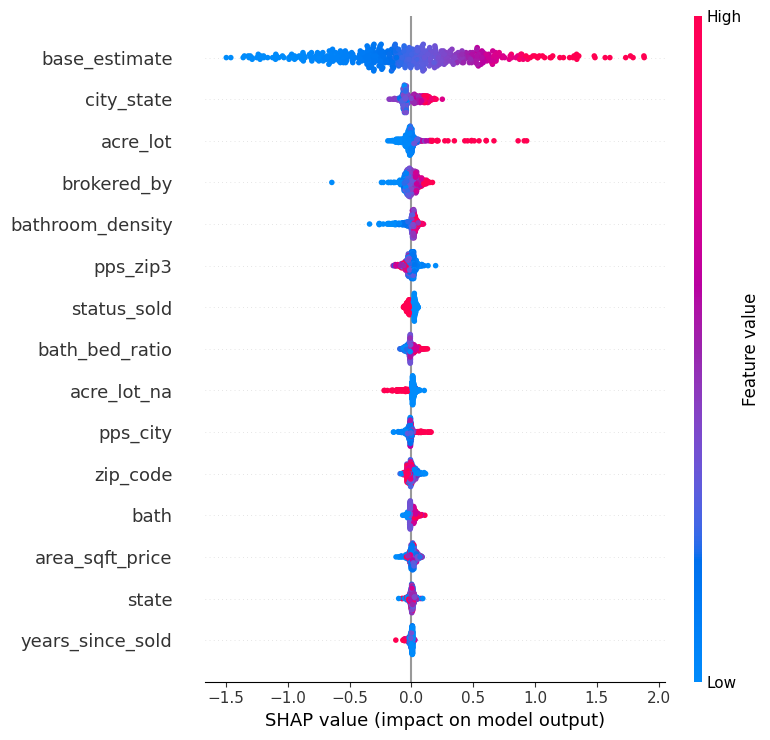

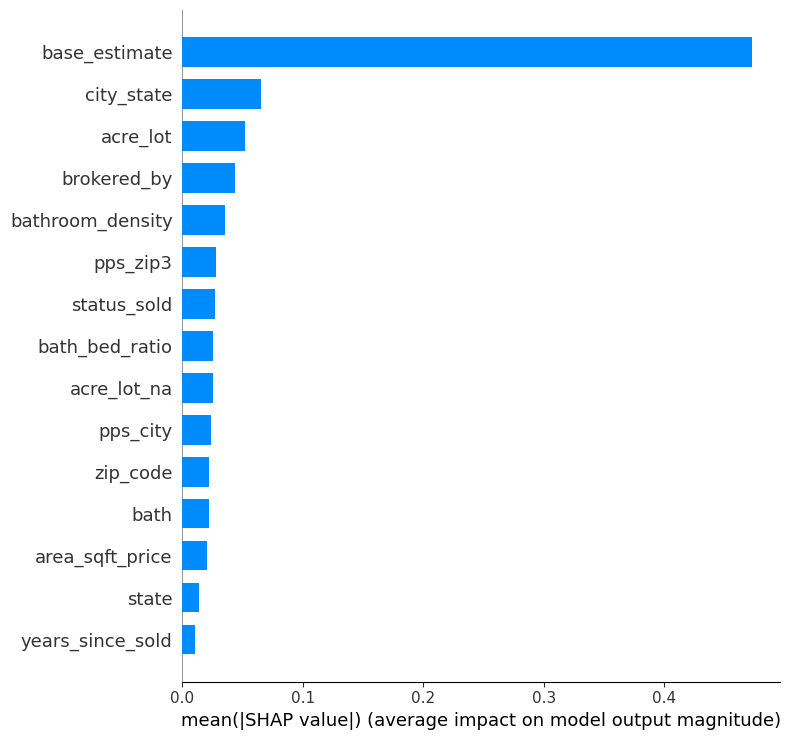

In [ ]:
X_shap = X_test.sample(n=min(500, len(X_test)), random_state=SEED)
X_shap_t = transform_until_model(FINAL["XGBoost"], X_shap)
model_xgb = FINAL["XGBoost"].named_steps["model"]
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer.shap_values(X_shap_t)
print("SHAP selesai untuk", len(X_shap), "test instances | shap", shap.__version__)

shap_importance = pd.DataFrame({
    "Feature": X_shap_t.columns,
    "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0),
    "XGB_gain_importance": model_xgb.feature_importances_,
}).sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
shap_importance.index += 1
save_table("table_shap_importance", shap_importance.reset_index(names="Rank"))
display(shap_importance.head(15).round(4))

for kind, fname in ((None, "shap_beeswarm.png"), ("bar", "shap_bar.png")):
    shap.summary_plot(shap_values, X_shap_t, plot_type=kind, max_display=15, show=False)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=300, bbox_inches="tight"); plt.show()

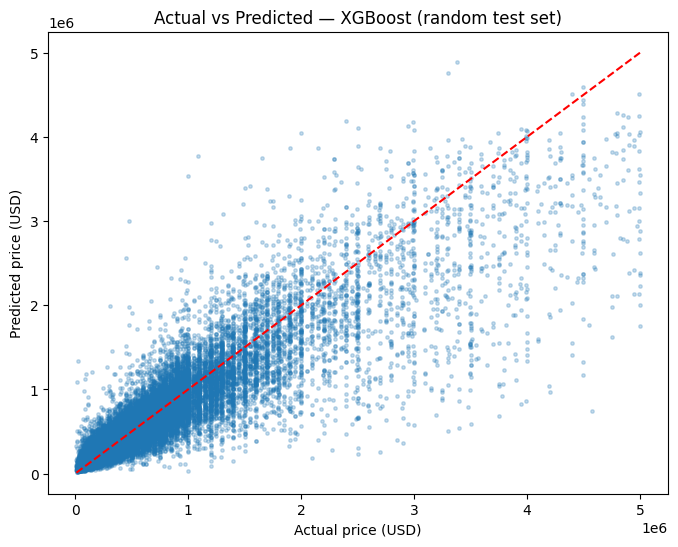

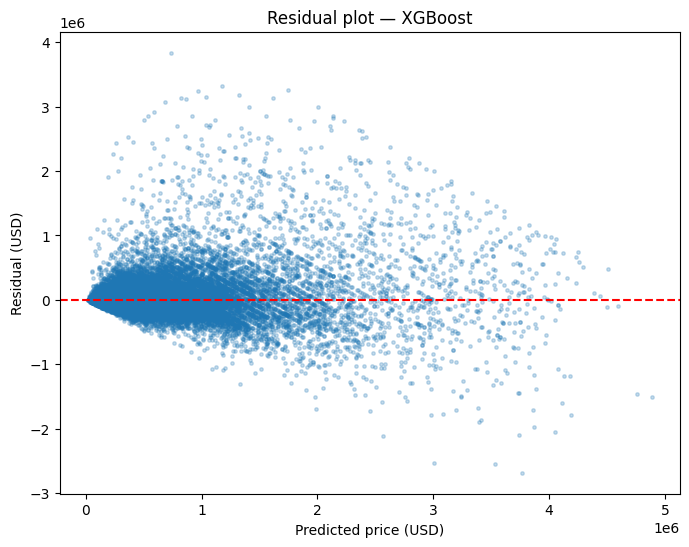

In [ ]:
# Plot final (XGBoost) — disimpan 300 dpi untuk manuskrip
y_act, y_hat = np.expm1(y_test.to_numpy()), np.expm1(PRED["XGBoost"])

plt.figure(figsize=(8, 6))
plt.scatter(y_act, y_hat, alpha=0.25, s=6)
lim = [min(y_act.min(), y_hat.min()), max(y_act.max(), y_hat.max())]
plt.plot(lim, lim, "r--"); plt.xlabel("Actual price (USD)"); plt.ylabel("Predicted price (USD)")
plt.title("Actual vs Predicted — XGBoost (random test set)")
plt.savefig(os.path.join(OUT_DIR, "actual_vs_predicted.png"), dpi=300, bbox_inches="tight"); plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_hat, y_act - y_hat, alpha=0.25, s=6); plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price (USD)"); plt.ylabel("Residual (USD)"); plt.title("Residual plot — XGBoost")
plt.savefig(os.path.join(OUT_DIR, "residuals.png"), dpi=300, bbox_inches="tight"); plt.show()

# **17. Ekspor Artefak (untuk manuskrip & repositori kode)**

In [ ]:
import shutil
json.dump({"fit_seconds": FIT_SECONDS, "best_params": BEST_PARAMS}, open(os.path.join(OUT_DIR, "run_summary.json"), "w"), indent=2)
archive = shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print("Isi", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))
print("Arsip:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Isi outputs : ['actual_vs_predicted.png', 'best_params.json', 'environment_config.json', 'negative_control.csv', 'optuna_trials_CatBoost.csv', 'optuna_trials_LightGBM.csv', 'optuna_trials_Random_Forest.csv', 'optuna_trials_XGBoost.csv', 'predictions_test.csv', 'residuals.png', 'run_summary.json', 'shap_bar.png', 'shap_beeswarm.png', 'table_ablation.csv', 'table_best_hyperparameters.csv', 'table_cleaning_steps.csv', 'table_geo_cv_folds.csv', 'table_geo_cv_summary.csv', 'table_main_random_test.csv', 'table_metrics_by_status.csv', 'table_metrics_property_overlap.csv', 'table_paired_comparison.csv', 'table_reporting_cv.csv', 'table_shap_importance.csv', 'train_test_gap.csv']
Arsip: /content/outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **18. Catatan untuk Manuscript (kerjakan SETELAH run penuh selesai)**

**Jangan menyalin angka lama.** Ganti dari `outputs/`:

| Bagian manuskrip | Sumber |
|---|---|
| Table 2 (perbandingan model) + semua kalimat peringkat | `table_main_random_test.csv` + blok "PERINGKAT PER METRIK" |
| Hyperparameter & trial | `table_best_hyperparameters.csv`, `optuna_trials_*.csv` → **30 trial**, bukan 15 |
| Ablation & angka "leaky vs leak-free" | `table_ablation.csv` (angka lama 0,6857 / 0,7916 / 0,0037 **tidak berlaku lagi**) |
| Train–test gap | `train_test_gap.csv` (pakai `train_R2_oof`) |
| Reporting-CV | `table_reporting_cv.csv` (acak vs per-ZIP) |
| Generalisasi geografis | `table_geo_cv_summary.csv` — laporkan **ketiga varian** dan batasi klaim sesuai hasil |
| Uji statistik | `table_paired_comparison.csv` (hapus Friedman–Nemenyi & semua kata "significantly outperforming") |
| Target / data | `table_cleaning_steps.csv`, `table_metrics_by_status.csv`, distribusi `status` → satu istilah target yang konsisten |
| Kebocoran | `negative_control.csv`, `table_metrics_property_overlap.csv` |
| SHAP | `table_shap_importance.csv` ("mean absolute SHAP", 500 test instances), gambar `shap_*.png` |
| Reproduksi | `environment_config.json`, `best_params.json`, `predictions_test.csv` → unggah kode + file ini ke repositori ber-DOI (mis. Zenodo) |